<a href="https://colab.research.google.com/github/Bigulac/Modelling-of-Dynamical-Systems-Mini-Project/blob/main/Code%20and%20Simulation%20of%20the%20Mini%20Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Utilities


In [ ]:
import numpy as np, sympy as sp
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch,FancyBboxPatch, Circle
import itertools
%matplotlib inline

### Question 1.4

Ellipse      max error 1.54e-07 um | max |u| 0.62 V | max |i| 0.040 A
Wine bottle  max error 1.20e-07 um | max |u| 2.69 V | max |i| 0.609 A


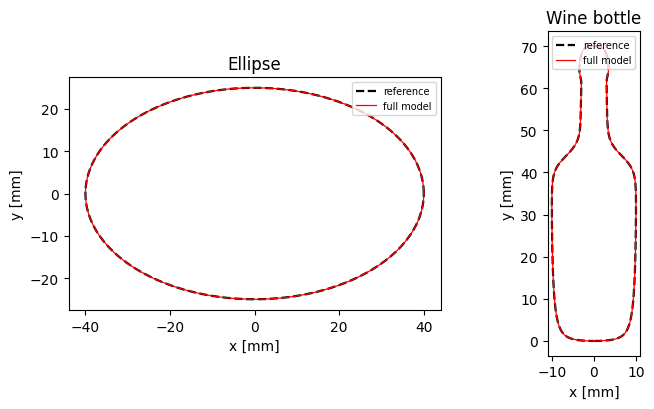

In [ ]:
# Q1.4 – Drawing shapes
rm, Lm, Rm, Km, Jm, m = 6e-3, 1e-3, 2.0, 0.05, 2e-6, 0.4
mur, mulx, muly = 1e-5, 2.0, 2.0
Jeq = Jm + 2*m*rm**2
a = mur + rm**2*(mulx + muly)
bx = mur + 2*rm**2*mulx
by = mur + 2*rm**2*muly
c = rm**2*(mulx - muly)
T, mm = 4.0, 1e-3
t = sp.symbols('t') # smooth time scaling, one lap in T seconds
tau = t/T
phi = 2*sp.pi*(10*tau**3 - 15*tau**4 + 6*tau**5)

# Drawing the two shapes - ellipse and wine bottle
ell = (40*mm*sp.cos(phi), 25*mm*sp.sin(phi))  # ellipse

# wine bottle
H, R, r, f = 70*mm, 10*mm, 3.2*mm, 4.0*mm      # height, body, neck, lip half-widths
y_sh, d_sh, y_lip, d_lip = 44*mm, 3.5*mm, 63*mm, 1.2*mm
k = 2.5                                         # flattens base and mouth
step = lambda y, c0, d: (1 + sp.tanh((y - c0)/d))/2
yb = H/2*(1 - sp.tanh(k*sp.cos(phi))/sp.tanh(k))
wb = R + (r - R)*step(yb, y_sh, d_sh) + (f - r)*step(yb, y_lip, d_lip)
bottle = (wb*sp.sin(phi), yb)

#Feedforward voltage and simulation of the full model
def u_ff(q, b):
    d1, d2, d3 = (sp.diff(q, t, n) for n in (1, 2, 3))
    return (Lm*Jeq*d3 + (Lm*b + Rm*Jeq)*d2 + (Rm*b + Km**2)*d1)/(rm*Km)

def to_fun(expr):
    g = sp.lambdify(t, expr, modules='numpy', cse=True)
    return lambda tt: g(tt)*np.ones_like(tt)

def run(shape):
    xr, yr = shape
    fx, fy = to_fun(xr), to_fun(yr)
    fux, fuy = to_fun(u_ff(xr, bx)), to_fun(u_ff(yr, by))

    def rhs(s_t, s):                                  # full 6-state model
        thl, thr, wl, wr, il, ir = s
        ux, uy = fux(s_t), fuy(s_t)                   # exact voltage, no interpolation
        ul, ur = (ux + uy)/2, (ux - uy)/2
        return [wl, wr,
                (Km*il - a*wl - c*wr)/Jeq,
                (Km*ir - c*wl - a*wr)/Jeq,
                (ul - Rm*il - Km*wl)/Lm,
                (ur - Rm*ir - Km*wr)/Lm]

    x0, y0 = float(fx(0.)), float(fy(0.))
    s0 = [(x0 + y0)/(2*rm), (x0 - y0)/(2*rm), 0, 0, 0, 0]
    tt = np.linspace(0, T, 4001)
    sol = solve_ivp(rhs, [0, T], s0, t_eval=tt, method='Radau',
                    rtol=1e-10, atol=1e-14)
    x = rm*(sol.y[0] + sol.y[1]);  y = rm*(sol.y[0] - sol.y[1])
    xr_, yr_ = fx(tt), fy(tt)
    UX, UY = fux(tt), fuy(tt)
    return dict(t=tt, xr=xr_, yr=yr_, x=x, y=y,
                err=np.hypot(x - xr_, y - yr_).max(),
                umax=np.abs(np.r_[(UX + UY)/2, (UX - UY)/2]).max(),
                imax=np.abs(sol.y[4:]).max())

res = {"Ellipse": run(ell), "Wine bottle": run(bottle)}
for name, d in res.items():
    print(f"{name:12s} max error {d['err']*1e6:.2e} um | max |u| {d['umax']:.2f} V | max |i| {d['imax']:.3f} A")


# Plotting the figures of ellipsoid and wine bottle
fig, axs = plt.subplots(1, 2, figsize=(8, 4.2))
for ax, (name, d) in zip(axs, res.items()):
    ax.plot(d['xr']/mm, d['yr']/mm, 'k--', lw=1.6, label='reference')
    ax.plot(d['x']/mm,  d['y']/mm,  'r',   lw=0.9, label='full model')
    ax.set_aspect('equal'); ax.set_title(name)
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]')
    ax.legend(loc='upper right', fontsize=7)
plt.tight_layout()
plt.savefig('fig_paths.png', dpi=200)
plt.show()


### Question 1.6

path length P = 206.9 mm, speed v = 51.7 mm/s, printing takes 4.0 s
thermal diffusivity alpha = 5.824e-08 m^2/s
tau = 3.25 s, effective T_inf = 49.1 C
h_air = 25.0, h_hotbed = 200.0 W/m2/K

Largest difference to the exact solution (no axial conduction): 0.43 K

  ds [mm]  dt [s]   t_cool [s]  t_unif [s]
    2.00  0.0200       12.48      19.08
    1.00  0.0100       12.51      19.12
    0.50  0.0050       12.52      19.13
    0.25  0.0025       12.51      19.13

Without axial conduction: t_cool = 12.52 s, t_unif = 19.16 s

Whole path printed at t = 4.0 s
Hottest point within 5 K of T_inf (49.1 C) at t = 12.5 s (8.5 s after printing)
Temperature uniform within 1 K at t = 19.1 s (15.1 s after printing)


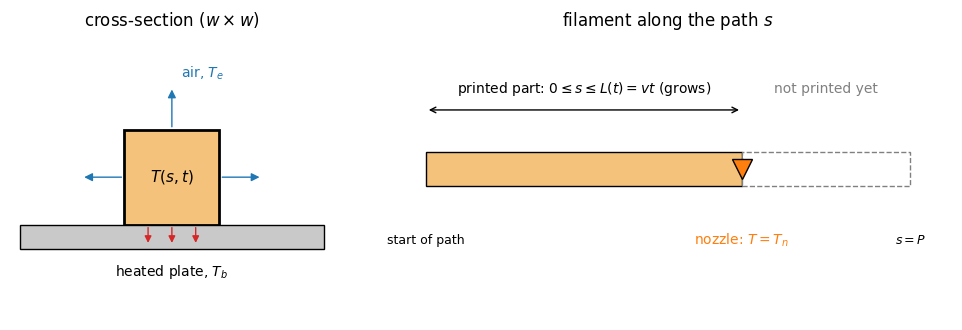

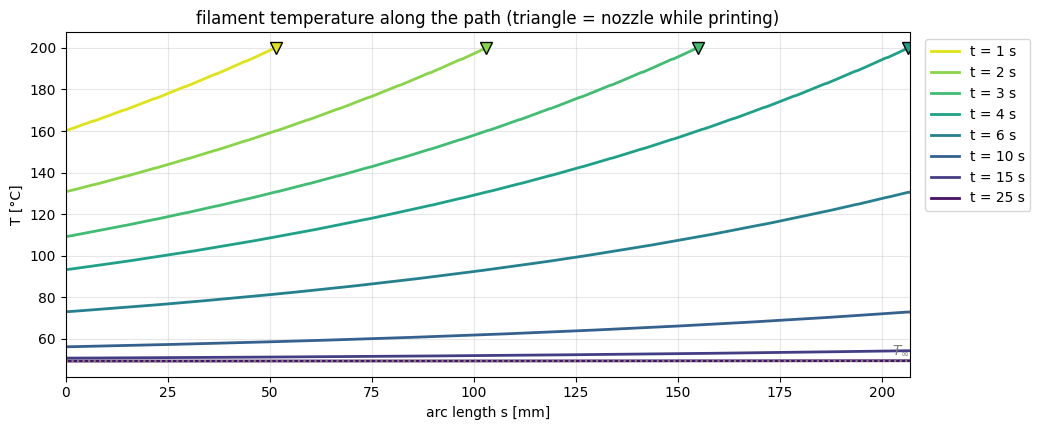

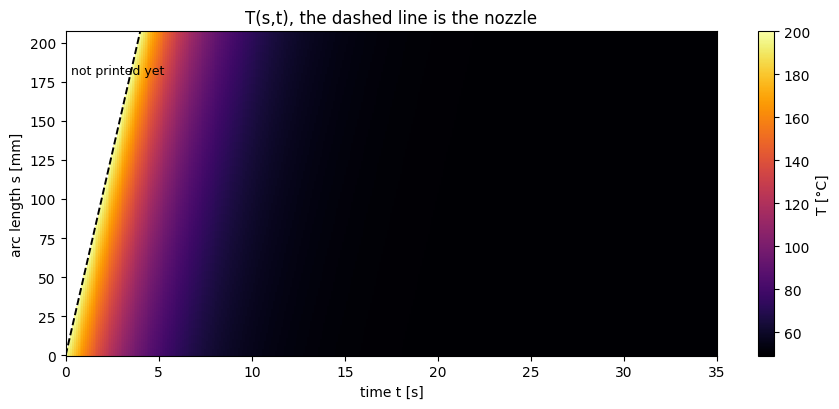

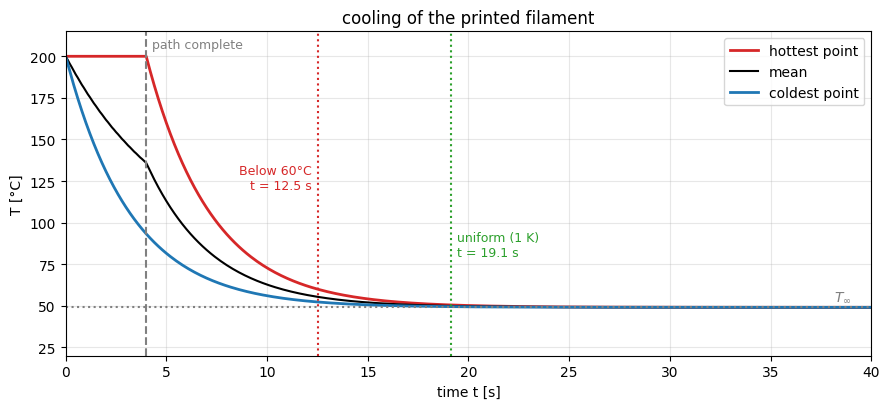

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# Parameters
w = 0.4e-3
rho, cp, k = 1240.0, 1800.0, 0.13
T_n, T_b, T_e = 200.0, 60.0, 20.0
h_air = 25.0                          # Top and two side faces [W/m2/K]
h_hotbed = 200.0                       # Bottom side effective contact coefficient with hotbed [W/m2/K]

A_el, B_el, T_lap = 40e-3, 25e-3, 4.0 # Elliptical printing path
th = np.linspace(0, 2*np.pi, 200001)
f = np.hypot(A_el*np.sin(th), B_el*np.cos(th))
P = np.sum((f[1:] + f[:-1]) / 2 * np.diff(th))
v = P / T_lap

# Thermal properties
alpha = k / (rho * cp)
tau = rho * cp * w / (h_hotbed + 3 * h_air)
T_inf = (3*h_air/(h_hotbed + 3*h_air)*T_e + h_hotbed/(h_hotbed + 3*h_air)*T_b)

print(f"path length P = {P*1e3:.1f} mm, "f"speed v = {v*1e3:.1f} mm/s, "f"printing takes {P/v:.1f} s")
print(f"thermal diffusivity alpha = {alpha:.3e} m^2/s")
print(f"tau = {tau:.2f} s, effective T_inf = {T_inf:.1f} C")
print(f"h_air = {h_air:.1f}, h_hotbed = {h_hotbed:.1f} W/m2/K")

# 1D PDE numerical simulation
def simulate(ds=0.5e-3, dt=0.005, t_end=40.0,rec=0.1, conduction=True):

    N = int(round(P/ds))
    s = np.arange(N + 1) * ds

    al = alpha if conduction else 0.0
    T = np.full(N + 1, T_n)

    times = [0.0]
    snaps = [T.copy()]
    nprint = [1]
    next_rec = rec

    for step in range(1, int(round(t_end/dt)) + 1):
        t = step * dt

        n = min(N + 1, int(v*t/ds) + 1) # Number of points printed so far
        printing = n < N + 1

        x = T[:n]
        lap = np.zeros(n)

        # Axial conduction along the filament
        if n > 2:
            lap[1:-1] = (
                x[2:] - 2*x[1:-1] + x[:-2]
            ) / ds**2

            # Insulated boundary at the start of the path
            lap[0] = 2*(x[1] - x[0]) / ds**2

            # Insulated endpoint once the path is complete
            lap[-1] = 2*(x[-2] - x[-1]) / ds**2

        cooling = (
            3*h_air*(x - T_e)
            + h_hotbed*(x - T_b)
        ) / (rho * cp * w)

        # Explicit Euler update
        T[:n] = x + dt * (al*lap - cooling)

        # Nozzle boundary condition at the moving printing front
        if printing:
            T[n - 1] = T_n

        if t >= next_rec - 1e-12:
            times.append(t)
            snaps.append(T.copy())
            nprint.append(n)
            next_rec += rec

    return {
        "t": np.array(times),
        "T": np.array(snaps),
        "s": s,
        "n": np.array(nprint)
    }


def evaluate(res, spread=1.0, below=60.0):

    t, T, n = res["t"], res["T"], res["n"]

    Tmax = np.array([
        T[i][:n[i]].max() for i in range(len(t))
    ])

    Tmin = np.array([
        T[i][:n[i]].min() for i in range(len(t))
    ])

    Tavg = np.array([
        T[i][:n[i]].mean() for i in range(len(t))
    ])

    done = n >= len(res["s"])

    def first_below(y, level):
        for i in range(1, len(t)):
            if done[i] and y[i] <= level < y[i-1]:
                return (
                    t[i-1]
                    + (y[i-1] - level)
                    / (y[i-1] - y[i])
                    * (t[i] - t[i-1])
                )
        return np.nan

    times = {
        "t_cool": first_below(Tmax, below),
        "t_unif": first_below(Tmax - Tmin, spread)
    }

    return times, Tmax, Tmin, Tavg

# sanitiy check without axial condition
r0 = simulate(conduction=False, t_end=12)
err = 0.0

for i, t in enumerate(r0["t"]):
    if t < P/v:
        continue

    exact = T_inf + (
        (T_n - T_inf)
        * np.exp(-(t - r0["s"]/v) / tau)
    )

    err = max(
        err,
        np.abs(r0["T"][i] - exact).max()
    )

print(
    f"\nLargest difference to the exact solution "
    f"(no axial conduction): {err:.2f} K"
)

print("\n  ds [mm]  dt [s]   t_cool [s]  t_unif [s]")
for ds, dt in [
    (2e-3, 0.02),
    (1e-3, 0.01),
    (0.5e-3, 0.005),
    (0.25e-3, 0.0025)
]:
    m_, *_ = evaluate(simulate(ds=ds, dt=dt))

    print(
        f"  {ds*1e3:6.2f}  {dt:6.4f}   "
        f"{m_['t_cool']:9.2f}  {m_['t_unif']:9.2f}"
    )

m_, *_ = evaluate(simulate(conduction=False))

print(
    f"\nWithout axial conduction: "
    f"t_cool = {m_['t_cool']:.2f} s, "
    f"t_unif = {m_['t_unif']:.2f} s"
)

res = simulate()  # Main simulation starts here
m, Tmax, Tmin, Tavg = evaluate(res)

t_p = P/v

print(f"\nWhole path printed at t = {t_p:.1f} s")

print(
    f"Hottest point within 5 K of T_inf ({T_inf:.1f} C) "
    f"at t = {m['t_cool']:.1f} s "
    f"({m['t_cool'] - t_p:.1f} s after printing)"
)

print(
    f"Temperature uniform within 1 K at "
    f"t = {m['t_unif']:.1f} s "
    f"({m['t_unif'] - t_p:.1f} s after printing)"
)

# Cross-section and filament along the path
fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(10, 3.4),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

a1.add_patch(Rectangle(
    (-0.5, -0.5), 1, 1,
    fc="#f4c27a", ec="k", lw=2
))

a1.add_patch(Rectangle(
    (-1.6, -0.75), 3.2, 0.25,
    fc="#c9c9c9", ec="k"
))

a1.text(
    0, -0.9, "heated plate, $T_b$",
    ha="center", va="top", fontsize=10
)

# Bottom-face heat exchange with the plate
for x0 in (-0.25, 0, 0.25):
    a1.add_patch(FancyArrowPatch(
        (x0, -0.5), (x0, -0.72),
        arrowstyle="-|>", mutation_scale=10,
        color="tab:red"
    ))

# Top and side faces exposed to air
for p, q in [
    ((0, 0.5), (0, 0.95)),
    ((0.5, 0), (0.95, 0)),
    ((-0.5, 0), (-0.95, 0))
]:
    a1.add_patch(FancyArrowPatch(
        p, q, arrowstyle="-|>",
        mutation_scale=12, color="tab:blue"
    ))

a1.text(
    0.1, 1.0, "air, $T_e$",
    color="tab:blue", fontsize=10, va="bottom"
)

a1.text(0, 0, "$T(s,t)$", ha="center", va="center", fontsize=11)

a1.set_xlim(-1.7, 1.7)
a1.set_ylim(-1.5, 1.5)
a1.set_aspect("equal")
a1.axis("off")
a1.set_title("cross-section ($w\\times w$)")

a2.add_patch(Rectangle(
    (0, -0.1), 3.0, 0.2,
    fc="#f4c27a", ec="k"
))

a2.add_patch(Rectangle(
    (3.0, -0.1), 1.6, 0.2,
    fc="white", ec="gray", ls="--"
))

a2.annotate(
    "", xy=(3.0, 0.35), xytext=(0, 0.35),
    arrowprops=dict(arrowstyle="<->")
)

a2.text(
    1.5, 0.45,
    "printed part: $0\\leq s\\leq L(t)=vt$ (grows)",
    ha="center"
)

a2.text(
    3.8, 0.45, "not printed yet",
    ha="center", color="gray"
)

a2.plot([3.0], [0], marker="v", color="tab:orange", ms=14, mec="k")
a2.text(3.0, -0.45, "nozzle: $T=T_n$", ha="center", color="tab:orange")
a2.text(0, -0.45, "start of path", ha="center", fontsize=9)
a2.text(4.6, -0.45, "$s=P$", ha="center", fontsize=9)

a2.set_xlim(-0.4, 5.0)
a2.set_ylim(-0.9, 0.8)
a2.axis("off")
a2.set_title("filament along the path $s$")

plt.tight_layout()
plt.savefig("fig_q16_model.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: Temperature profiles along the path
snap = [1, 2, 3, 4, 6, 10, 15, 25]
cols = plt.cm.viridis_r(np.linspace(0.05, 0.95, len(snap)))

fig, ax = plt.subplots(figsize=(10.5, 4.4))

for ts, c in zip(snap, cols):
    i = np.argmin(np.abs(res["t"] - ts))
    n = res["n"][i]

    ax.plot(
        res["s"][:n]*1e3, res["T"][i][:n],
        color=c, lw=2, label=f"t = {ts} s"
    )

    if n < len(res["s"]):
        ax.plot(
            res["s"][n-1]*1e3, T_n,
            "v", color=c, ms=8, mec="k"
        )

ax.axhline(T_inf, color="gray", ls=":")
ax.text(P*1e3, T_inf + 3, "$T_\\infty$", ha="right", color="gray")

ax.set_xlabel("arc length s [mm]")
ax.set_ylabel("T [°C]")
ax.set_xlim(0, P*1e3)
ax.set_title("filament temperature along the path (triangle = nozzle while printing)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig_q16_profiles.png", dpi=200)
plt.show()

# Figure 3: Temperature field T(s,t)
Tm = res["T"].copy()

for i in range(len(res["t"])):
    Tm[i, res["n"][i]:] = np.nan

fig, ax = plt.subplots(figsize=(9, 4.2))

pc = ax.pcolormesh(
    res["t"], res["s"]*1e3, Tm.T,
    cmap="inferno", shading="auto",
    vmin=T_inf, vmax=T_n
)

tl = np.linspace(0, t_p, 50)
ax.plot(tl, v*tl*1e3, "k--", lw=1.4)
ax.text(0.3, P*1e3*0.88, "not printed yet", va="center", fontsize=9)

ax.set_xlim(0, 35)
ax.set_xlabel("time t [s]")
ax.set_ylabel("arc length s [mm]")

fig.colorbar(pc, label="T [°C]")
ax.set_title("T(s,t), the dashed line is the nozzle")

plt.tight_layout()
plt.savefig("fig_q16_field.png", dpi=200)
plt.show()

# Figure 4: Hottest, mean and coldest temperatures
fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(res["t"], Tmax, color="tab:red", lw=2, label="hottest point")
ax.plot(res["t"], Tavg, color="k", lw=1.5, label="mean")
ax.plot(res["t"], Tmin, color="tab:blue", lw=2, label="coldest point")

ax.axhline(T_inf, color="gray", ls=":")
ax.text(39, T_inf + 4, "$T_\\infty$", ha="right", color="gray")

ax.axvline(t_p, color="gray", ls="--")
ax.text(t_p + 0.3, 205, "path complete", color="gray", fontsize=9)

ax.axvline(m["t_cool"], color="tab:red", ls=":")
ax.text(
    m["t_cool"] - 0.3, 120,
    f"Below 60°C\nt = {m['t_cool']:.1f} s",
    color="tab:red", fontsize=9, ha="right"
)

ax.axvline(m["t_unif"], color="tab:green", ls=":")
ax.text(
    m["t_unif"] + 0.3, 80,
    f"uniform (1 K)\nt = {m['t_unif']:.1f} s",
    color="tab:green", fontsize=9
)

ax.set_xlim(0, 40)
ax.set_ylim(20, 215)
ax.set_xlabel("time t [s]")
ax.set_ylabel("T [°C]")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
ax.set_title("cooling of the printed filament")

plt.tight_layout()
plt.savefig("fig_q16_timeline.png", dpi=200)
plt.show()


### Question 2.1

step  input      state       output
   0  -          PRINTING    print object, heater on
   1  -          PRINTING    print object, heater on
   2  C,F        STOP        stop printing, store (xp, yp)
   3  C          STOP        stop printing, store (xp, yp)
   4  saved      MOVE        move head to wipe tower (0, 0)
   5  arrived    WIPE        wipe excess filament
   6  F          WIPE        wipe excess filament
   7  -          WIPE        wipe excess filament
   8  wiped      NOZZLE OFF  heater off
   9  off        LOAD        load new filament
  10  loaded     NOZZLE ON   heater on, wait for print temperature
  11  -          NOZZLE ON   heater on, wait for print temperature
  12  -          NOZZLE ON   heater on, wait for print temperature
  13  hot        RESUME      move back to (xp, yp), continue printing
  14  back       PRINTING    print object, heater on
  15  C          STOP        stop printing, store (xp, yp)


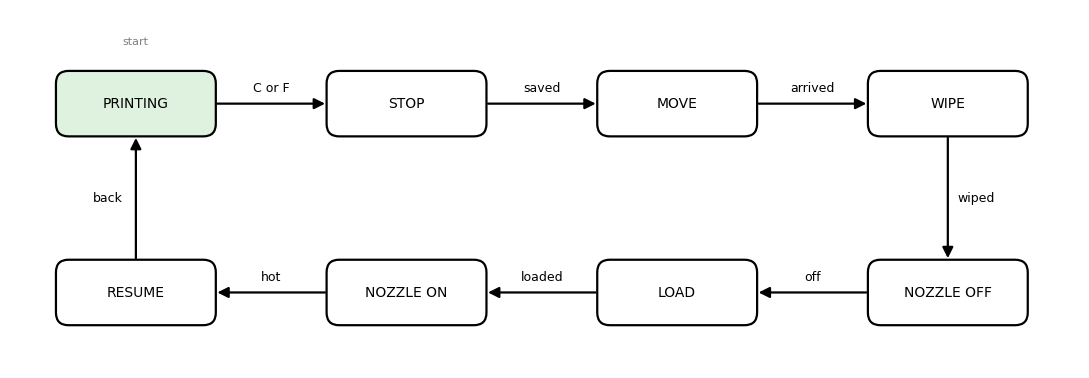

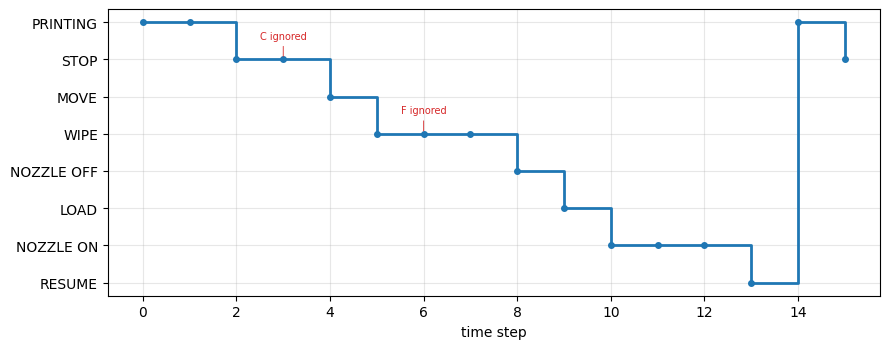

In [ ]:
OUTPUT = {
    "PRINTING":   "print object, heater on",
    "STOP":       "stop printing, store (xp, yp)",
    "MOVE":       "move head to wipe tower (0, 0)",
    "WIPE":       "wipe excess filament",
    "NOZZLE OFF": "heater off",
    "LOAD":       "load new filament",
    "NOZZLE ON":  "heater on, wait for print temperature",
    "RESUME":     "move back to (xp, yp), continue printing",
}

# (state, input) -> next state; this is delta.

DELTA = {
    ("PRINTING",   "C"):       "STOP",
    ("PRINTING",   "F"):       "STOP",
    ("STOP",       "saved"):   "MOVE",
    ("MOVE",       "arrived"): "WIPE",
    ("WIPE",       "wiped"):   "NOZZLE OFF",
    ("NOZZLE OFF", "off"):     "LOAD",
    ("LOAD",       "loaded"):  "NOZZLE ON",
    ("NOZZLE ON",  "hot"):     "RESUME",
    ("RESUME",     "back"):    "PRINTING",
}

class FilamentFSM:
    def __init__(self):
        self.state = "PRINTING"

    def step(self, inputs):
        for s in inputs:
            nxt = DELTA.get((self.state, s))
            if nxt is not None:
                self.state = nxt
                break                       # one transition per time step
        return OUTPUT[self.state]

# Test run
run = [
    set(),                 # normal printing
    {"C", "F"},            # colour change and spool finished at the same time
    {"C"},                 # extra request during STOP: ignored
    {"saved"}, {"arrived"},
    {"F"},                 # request during WIPE: ignored
    set(),                 # wiping not done yet: stay in WIPE
    {"wiped"}, {"off"}, {"loaded"},
    set(), set(),          # nozzle still heating: stay in NOZZLE ON
    {"hot"}, {"back"},
    {"C"},                 # a new request is accepted again in PRINTING
]

m = FilamentFSM()
history = [m.state]
print(f"{'step':>4}  {'input':<10} {'state':<11} output")
print(f"{0:>4}  {'-':<10} {m.state:<11} {OUTPUT[m.state]}")
for k, inp in enumerate(run, 1):
    out = m.step(inp)
    history.append(m.state)
    print(f"{k:>4}  {','.join(sorted(inp)) or '-':<10} {m.state:<11} {out}")

# Figure 1: plotting the state diagram
pos = {"PRINTING": (0, 0), "STOP": (4.3, 0), "MOVE": (8.6, 0), "WIPE": (12.9, 0),
       "NOZZLE OFF": (12.9, -3), "LOAD": (8.6, -3), "NOZZLE ON": (4.3, -3), "RESUME": (0, -3)}
w, h = 2.5, 1.0

fig, ax = plt.subplots(figsize=(11, 4.2))
for name, (x, y) in pos.items():
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.2",
                                fc="#dff2df" if name == "PRINTING" else "white", ec="k", lw=1.6))
    ax.text(x, y, name, ha="center", va="center", fontsize=10)

def arrow(src, dst, label, label_off=(0, 0.25)):
    (x1, y1), (x2, y2) = pos[src], pos[dst]
    if y1 == y2:                         # horizontal arrow between box edges
        s = 1 if x2 > x1 else -1
        q1, p2 = (x1 + s*w/2, y1), (x2 - s*w/2, y2)
    else:                                # vertical arrow
        s = 1 if y2 > y1 else -1
        q1, p2 = (x1, y1 + s*h/2), (x2, y2 - s*h/2)
    ax.add_patch(FancyArrowPatch(q1, p2, arrowstyle="-|>", mutation_scale=16, lw=1.6, color="k"))
    ax.text((q1[0] + p2[0])/2 + label_off[0], (q1[1] + p2[1])/2 + label_off[1],
            label, ha="center", va="center", fontsize=9)

# made changes so that the arrows are read off DELTA, so the figure always matches the code
labels = {}
for (s, inp), d in DELTA.items():
    labels.setdefault((s, d), []).append(inp)
for (s, d), inps in labels.items():
    off = (0.45, 0) if pos[s][0] == pos[d][0] and pos[s][1] != pos[d][1] and s == "WIPE" else \
          (-0.45, 0) if pos[s][0] == pos[d][0] else (0, 0.25)
    arrow(s, d, " or ".join(inps), off)

ax.text(0, 0.95, "start", ha="center", fontsize=8, color="gray")
ax.set_xlim(-2, 15); ax.set_ylim(-4.2, 1.5); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("fig_fsm.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2 :Plotting the state over time for the test run
order = list(OUTPUT)
yidx = [order.index(s) for s in history]
steps = list(range(len(history)))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(steps, yidx, where="post", color="tab:blue", lw=2)
ax.plot(steps, yidx, "o", color="tab:blue", ms=4)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel("time step"); ax.grid(alpha=0.3)

# mark the inputs that were ignored (the machine stayed in its state)
for k, inp in enumerate(run, 1):
    if inp and history[k] == history[k-1]:
        ax.annotate(",".join(sorted(inp)) + " ignored", (k, yidx[k]), xytext=(k, yidx[k] - 0.55),
                    ha="center", fontsize=7, color="tab:red",
                    arrowprops=dict(arrowstyle="-", color="tab:red", lw=0.6))
plt.tight_layout()
plt.savefig("fig_fsm_run.png", dpi=200)
plt.show()


### Question 2.2

states: ['q0', 'q0', 'q0', 'q0', 'q1', 'q1', 'q3'] -> accepted: True
(a) 87381 sequences checked, mismatches: 0
(b) 8176 head runs, 4898 accepted, accepted but not at origin: 0


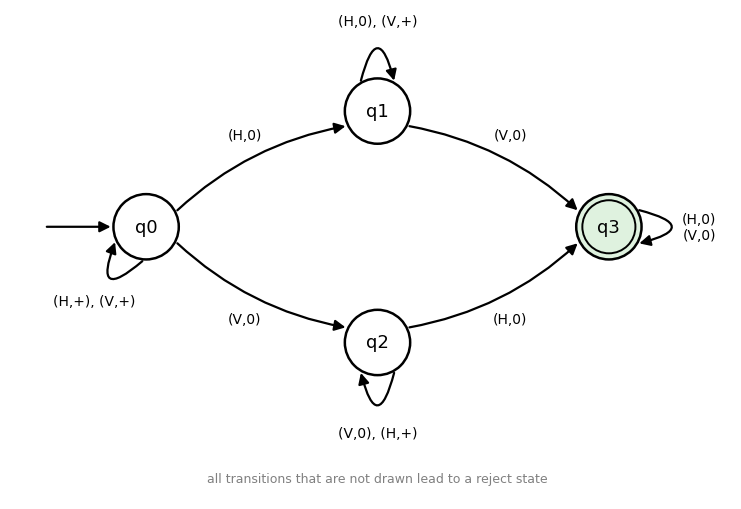

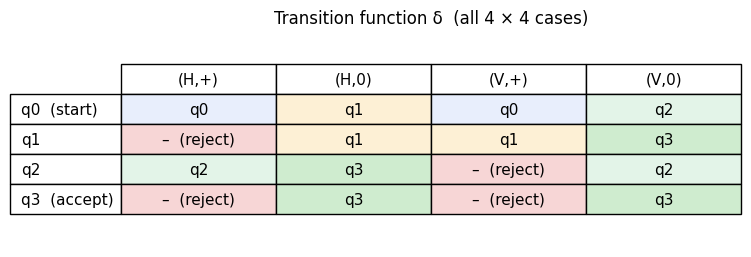

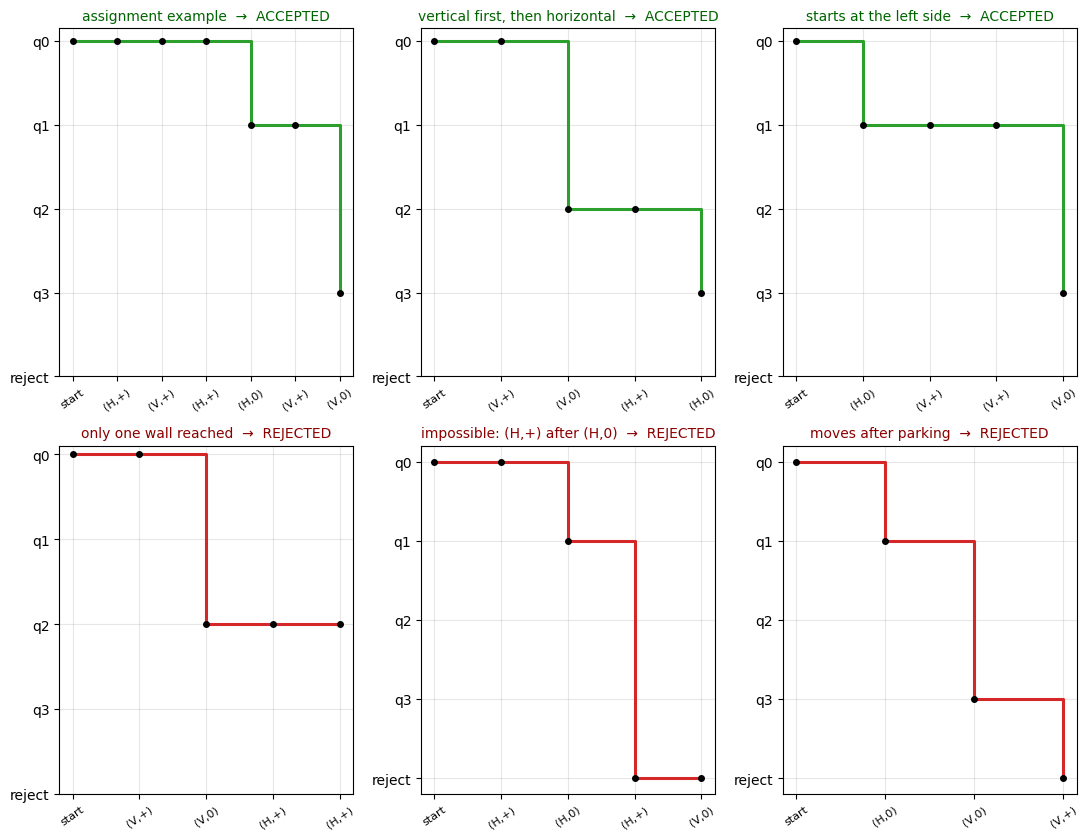

sensor readings: [('H', '+'), ('V', '+'), ('H', '+'), ('H', '0'), ('V', '+'), ('V', '0')] -> accepted: True


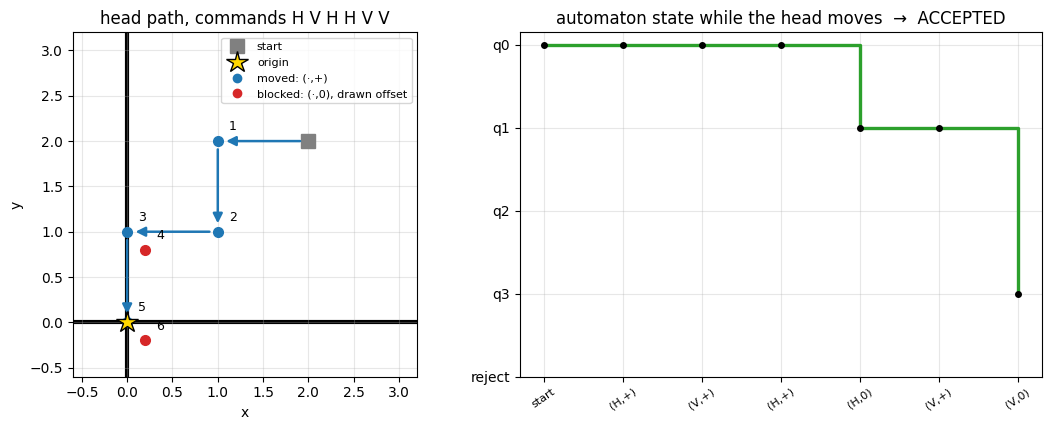

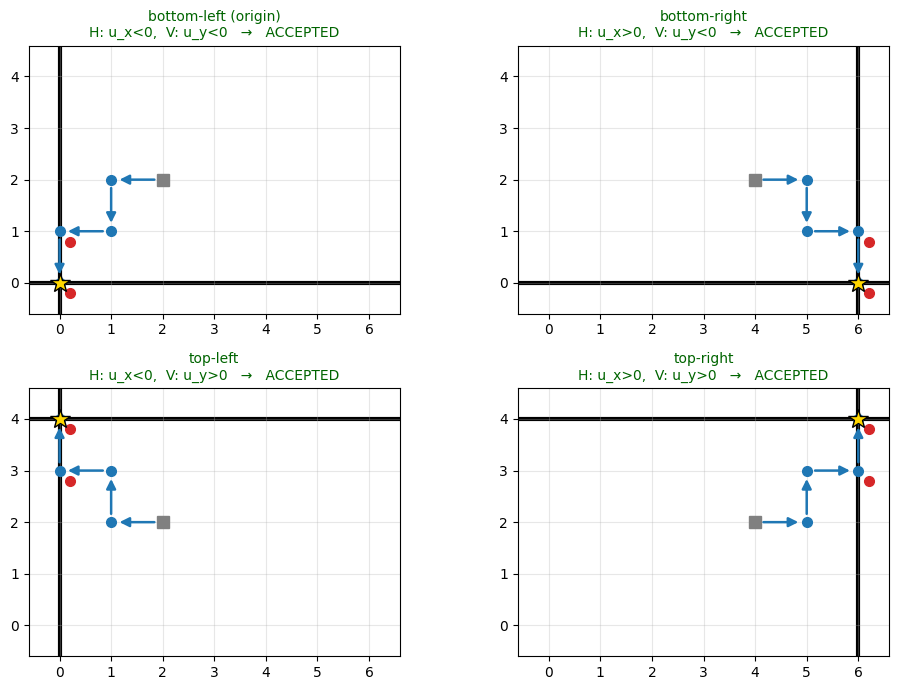

In [ ]:
SIGMA = [("H", "+"), ("H", "0"), ("V", "+"), ("V", "0")]
STATES = ["q0", "q1", "q2", "q3"]
START, ACCEPT = "q0", {"q3"}
MEANING = {"q0": "no wall reached", "q1": "left side reached",
           "q2": "bottom reached",  "q3": "both reached = parked"}

# commands to go from one state to next on reciving input. Anything not listed goes to "reject".
DELTA = {
    ("q0", ("H", "+")): "q0", ("q0", ("V", "+")): "q0",
    ("q0", ("H", "0")): "q1", ("q0", ("V", "0")): "q2",

    ("q1", ("H", "0")): "q1", ("q1", ("V", "+")): "q1",
    ("q1", ("V", "0")): "q3",

    ("q2", ("V", "0")): "q2", ("q2", ("H", "+")): "q2",
    ("q2", ("H", "0")): "q3",

    ("q3", ("H", "0")): "q3", ("q3", ("V", "0")): "q3",
}

def trace(seq):
    q, tr = START, [START]
    for s in seq:
        q = DELTA.get((q, s), "reject") if q != "reject" else "reject"        # if rejected, stay in rejected
        tr.append(q)
    return tr

def accepts(seq):
    return trace(seq)[-1] in ACCEPT

# the example from the assignment as a test case
ex = [("H","+"), ("V","+"), ("H","+"), ("H","0"), ("V","+"), ("V","0")]
print("states:", trace(ex), "-> accepted:", accepts(ex))

def reference(seq):
    hz = vz = False
    for M, m in seq:
        if M == "H":
            if m == "+" and hz: return False
            if m == "0": hz = True
        else:
            if m == "+" and vz: return False
            if m == "0": vz = True
    return hz and vz

n = bad = 0
for L in range(9):
    for seq in itertools.product(SIGMA, repeat=L):
        n += 1; bad += accepts(seq) != reference(seq)
print(f"(a) {n} sequences checked, mismatches: {bad}")

# as a physical check we can use a head on a grid that always moves towards the origin.
#The fact that the state appears as accepted shows that the head must really be at the origin.
def simulate(x, y, cmds):
    out = []
    for c in cmds:
        if c == "H":
            if x > 0: x -= 1; out.append(("H", "+"))
            else:             out.append(("H", "0"))
        else:
            if y > 0: y -= 1; out.append(("V", "+"))
            else:             out.append(("V", "0"))
    return x, y, out

runs = accepted = unsound = 0
for x0, y0 in itertools.product(range(4), repeat=2):
    for L in range(9):
        for cmds in itertools.product("HV", repeat=L):
            x, y, out = simulate(x0, y0, cmds)
            runs += 1
            if accepts(out):
                accepted += 1
                unsound += (x, y) != (0, 0)
print(f"(b) {runs} head runs, {accepted} accepted, accepted but not at origin: {unsound}")

#Figure 1 : Plotting the automaton diagram
pos = {"q0": np.array([0.0, 0.0]), "q1": np.array([3.4, 1.7]),
       "q2": np.array([3.4, -1.7]), "q3": np.array([6.8, 0.0])}
R = 0.48

fig, ax = plt.subplots(figsize=(10, 5.2))
for q, p in pos.items():
    ax.add_patch(Circle(p, R, fc="#dff2df" if q in ACCEPT else "white", ec="k", lw=1.8, zorder=3))
    if q in ACCEPT:
        ax.add_patch(Circle(p, R - 0.09, fc="none", ec="k", lw=1.4, zorder=4))
    ax.text(*p, q, ha="center", va="center", fontsize=13, zorder=5)

# start arrow
ax.add_patch(FancyArrowPatch((-1.5, 0), (-R, 0), arrowstyle="-|>", mutation_scale=16, lw=1.6, color="k"))

def edge(a, b, label, rad, off=0.28):
    d = pos[b] - pos[a]; u = d / np.linalg.norm(d)
    q1, p2 = pos[a] + u * R, pos[b] - u * R
    ax.add_patch(FancyArrowPatch(q1, p2, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=16, lw=1.6, color="k", zorder=2))
    mid = (q1 + p2) / 2; nrm = np.array([-u[1], u[0]])      # left normal
    s = -np.sign(rad) if rad != 0 else 1                     # label on the bulging side
    ax.text(*(mid + s * nrm * (abs(rad) * np.linalg.norm(d) / 2 + off)), label,
            ha="center", va="center", fontsize=10)

def loop(q, ang, label):
    dirv = np.array([np.cos(np.radians(ang)), np.sin(np.radians(ang))])
    A = pos[q] + R * np.array([np.cos(np.radians(ang + 32)), np.sin(np.radians(ang + 32))])
    B = pos[q] + R * np.array([np.cos(np.radians(ang - 32)), np.sin(np.radians(ang - 32))])
    mid = (A + B) / 2; dx, dy = B - A
    ctrl_plus = np.array([mid[0] + dy, mid[1] - dx])        # control point for rad = +1
    rad = 2.0 if np.dot(ctrl_plus - mid, dirv) > 0 else -2.0
    ax.add_patch(FancyArrowPatch(A, B, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=16, lw=1.6, color="k", zorder=2))
    ax.text(*(pos[q] + (R + 0.85) * dirv), label, ha="center", va="center", fontsize=10)

edge("q0", "q1", "(H,0)", -0.15); edge("q0", "q2", "(V,0)", 0.15)
edge("q1", "q3", "(V,0)", -0.15); edge("q2", "q3", "(H,0)", 0.15)
loop("q0", 235, "(H,+), (V,+)"); loop("q1", 90, "(H,0), (V,+)")
loop("q2", -90, "(V,0), (H,+)");  loop("q3", 0, "(H,0)\n(V,0)")

ax.text(3.4, -3.75, "all transitions that are not drawn lead to a reject state",
        ha="center", fontsize=9, color="gray")
ax.set_xlim(-2, 8.6); ax.set_ylim(-4.0, 3.2); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.savefig("fig_dfa.png", dpi=200, bbox_inches="tight"); plt.show()
# Figure 2 : complete transition table
colors = {"q0": "#e8eefc", "q1": "#fdf0d5", "q2": "#e3f4e8", "q3": "#cfeccf", "reject": "#f7d6d6"}
cols = [f"({M},{m})" for M, m in SIGMA]
cell, cc = [], []
for q in STATES:
    row, crow = [], []
    for s in SIGMA:
        nxt = DELTA.get((q, s), "reject")
        row.append("–  (reject)" if nxt == "reject" else nxt); crow.append(colors[nxt])
    cell.append(row); cc.append(crow)

fig, ax = plt.subplots(figsize=(8, 2.8)); ax.axis("off")
rowlab = [f"{q}{'  (start)' if q == START else ''}{'  (accept)' if q in ACCEPT else ''}" for q in STATES]
tb = ax.table(cellText=cell, cellColours=cc, rowLabels=rowlab, colLabels=cols, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 1.8)
ax.set_title("Transition function δ  (all 4 × 4 cases)", fontsize=12)
plt.savefig("fig_dfa_table.png", dpi=200, bbox_inches="tight"); plt.show()
# Figure 3 : plotting the state traces of example sequences
examples = {
    "assignment example":              ex,
    "vertical first, then horizontal": [("V","+"),("V","0"),("H","+"),("H","0")],
    "starts at the left side":         [("H","0"),("V","+"),("V","+"),("V","0")],
    "only one wall reached":           [("V","+"),("V","0"),("H","+"),("H","+")],
    "impossible: (H,+) after (H,0)":   [("H","+"),("H","0"),("H","+"),("V","0")],
    "moves after parking":             [("H","0"),("V","0"),("V","+")],
}
levels = ["q0", "q1", "q2", "q3", "reject"]
fig, axs = plt.subplots(2, 3, figsize=(11, 8.5))
for ax, (name, seq) in zip(axs.ravel(), examples.items()):
    tr = trace(seq); ok = accepts(seq)
    yy = [levels.index(q) for q in tr]
    ax.step(range(len(yy)), yy, where="post", color="tab:green" if ok else "tab:red", lw=2.2)
    ax.plot(range(len(yy)), yy, "o", color="k", ms=4)
    ax.set_yticks(range(5)); ax.set_yticklabels(levels); ax.invert_yaxis()
    ax.set_xticks(range(len(yy)))
    ax.set_xticklabels(["start"] + [f"({M},{m})" for M, m in seq], rotation=35, fontsize=8)
    ax.set_title(f"{name}  →  {'ACCEPTED' if ok else 'REJECTED'}", fontsize=10,
                 color="darkgreen" if ok else "darkred")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_dfa_traces.png", dpi=200); plt.show()

# Figure 4 – a simulated head on a grid
def move(x, y, cmds, target=(0, 0), size=(5, 4)):
    """Head on a grid. Each command moves one cell towards the target wall of that axis
    unless it is already there; the sensor reads '+' if it moved and '0' if blocked."""
    X, Y = size; tx, ty = target
    sx = 1 if tx > x else -1
    sy = 1 if ty > y else -1
    P, S = [(x, y)], []
    for c in cmds:
        if c == "H":
            if x != tx: x += sx; S.append(("H", "+"))
            else:       S.append(("H", "0"))
        else:
            if y != ty: y += sy; S.append(("V", "+"))
            else:       S.append(("V", "0"))
        P.append((x, y))
    return P, S

cmds = "HVHHVV"                              # the assignment's example, started at (2, 2)
def draw_path(ax, P, S, number=True):
    """Arrows between cells; blue dot = head moved, red dot = blocked (offset so it stays visible)."""
    seen = {}
    for k in range(1, len(P)):
        (x1, y1), (x2, y2) = P[k-1], P[k]
        if (x1, y1) != (x2, y2):
            ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14,
                                         lw=1.8, color="tab:blue", shrinkA=6, shrinkB=6, zorder=4))
        moved = S[k-1][1] == "+"
        n = seen.get((x2, y2), 0) if not moved else 0
        off = np.array([0.0, 0.0]) if moved else np.array([0.2, -0.2]) * (n + 1)
        if not moved: seen[(x2, y2)] = n + 1
        ax.plot(x2 + off[0], y2 + off[1], "o", color="tab:blue" if moved else "tab:red", ms=7, zorder=6)
        if number: ax.text(x2 + off[0] + 0.12, y2 + off[1] + 0.12, str(k), fontsize=9, zorder=7)

P, S = move(2, 2, cmds)
print("sensor readings:", S, "-> accepted:", accepts(S))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
a1.axvline(0, color="k", lw=3, zorder=1); a1.axhline(0, color="k", lw=3, zorder=1)          # left and bottom wall
draw_path(a1, P, S)
a1.plot(*P[0], "s", color="gray", ms=10, label="start")
a1.plot(0, 0, "*", color="gold", ms=16, mec="k", label="origin", zorder=6)
a1.plot([], [], "o", color="tab:blue", label="moved: (·,+)"); a1.plot([], [], "o", color="tab:red", label="blocked: (·,0), drawn offset")
a1.set_xlim(-0.6, 3.2); a1.set_ylim(-0.6, 3.2); a1.set_aspect("equal"); a1.grid(alpha=0.3)
a1.set_title("head path, commands " + " ".join(cmds)); a1.legend(fontsize=8, loc="upper right")
a1.set_xlabel("x"); a1.set_ylabel("y")

tr = trace(S); yy = [levels.index(q) for q in tr]
a2.step(range(len(yy)), yy, where="post", color="tab:green", lw=2.4); a2.plot(range(len(yy)), yy, "ko", ms=4)
a2.set_yticks(range(5)); a2.set_yticklabels(levels); a2.invert_yaxis()
a2.set_xticks(range(len(yy))); a2.set_xticklabels(["start"] + [f"({M},{m})" for M, m in S], rotation=35, fontsize=8)
a2.set_title("automaton state while the head moves  →  ACCEPTED"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_dfa_head.png", dpi=200); plt.show()

#Figure 5 – plotting of the same automaton for all four corner
size = (6, 4)
corners = {  # target corner: (tx, ty), start two cells away from each wall, label rule
    "bottom-left (origin)": ((0, 0),       (2, 2), "H: u_x<0,  V: u_y<0"),
    "bottom-right":         ((size[0], 0), (size[0]-2, 2), "H: u_x>0,  V: u_y<0"),
    "top-left":             ((0, size[1]), (2, size[1]-2), "H: u_x<0,  V: u_y>0"),
    "top-right":            (size,         (size[0]-2, size[1]-2), "H: u_x>0,  V: u_y>0"),
}
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for ax, (name, ((tx, ty), (x0, y0), rule)) in zip(axs.ravel(), corners.items()):
    P, S = move(x0, y0, "HVHHVV", target=(tx, ty), size=size)   # same command pattern
    ok = accepts(S)
    ax.axvline(tx, color="k", lw=3, zorder=1); ax.axhline(ty, color="k", lw=3, zorder=1)
    draw_path(ax, P, S, number=False)
    ax.plot(*P[0], "s", color="gray", ms=9); ax.plot(tx, ty, "*", color="gold", ms=15, mec="k", zorder=6)
    ax.set_xlim(-0.6, size[0] + 0.6); ax.set_ylim(-0.6, size[1] + 0.6); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_title(f"{name}\n{rule}   →   {'ACCEPTED' if ok else 'REJECTED'}", fontsize=10,
                 color="darkgreen" if ok else "darkred")
plt.tight_layout(); plt.savefig("fig_dfa_corners.png", dpi=200); plt.show()



### Question 3.1

In [ ]:
m = 0.4
c = rm**2*(mulx - muly)
a = mur + rm**2*(mulx + muly)

# Nozzle parameters
Ln, Cn, Rn, Ctn, Rtn, Te = 1e-3, 100e-6, 14.4, 20.0, 4.5, 20.0

# Hybrid systems constants
T_min   = 180.0     # Tn low threshold
U_ON    = 24.0
omega_max = 200.0          # [rad/s] speed limit of the motors
print_area_s    = 0.200            # [m] printing area 200 x 200 mm, origin = wipe tower = lower left corner

# Print ellipse 4 times to have time for events
xc, yc = 0.060, 0.045
N_laps, Om, T_ramp = 4, 2*np.pi/4, 0.5
Phi_end = 2*np.pi*N_laps

t_save, t_wipe, t_load = 0.1, 2.0, 5.0    # timers for modes

v_move = 0.10
u_home = 0.6
Ts = 0.01
t_hold = 0.2
eps_w = 0.2     # zero speed threshold

# external event signals: (time, name)
ext_q3 = [(5.0, 'C'), (14.0, 'F'), (63.0, 'F')]
T_END = 140.0

In [ ]:
S  = lambda u: 10*u**3 - 15*u**4 + 6*u**5          # smooth 0 -> 1 with zero speed and acceleration at both ends
S1 = lambda u: 30*u**2 - 60*u**3 + 30*u**4
S2 = lambda u: 60*u - 180*u**2 + 120*u**3
S3 = lambda u: 60 - 360*u + 360*u**2

def u_ff(d, b):
    return (Lm*Jeq*d[2] + (Lm*b + Rm*Jeq)*d[1] + (Rm*b + Km**2)*d[0])/(rm*Km) # ff voltage, d = (xdot, xddot, x3dot)

class PrintRef:
    # ellipse with progress variable phi; starts at rest from phi0 with a smooth speed ramp
    def __init__(s, t0, phi0): s.t0, s.phi0 = t0, phi0
    def phi(s, t):
        tau = t - s.t0
        if tau < T_ramp:
            u = tau/T_ramp
            return (s.phi0 + Om*T_ramp*(2.5*u**4 - 3*u**5 + u**6), Om*S(u), Om*S1(u)/T_ramp, Om*S2(u)/T_ramp**2)
        return (s.phi0 + Om*(0.5*T_ramp + tau - T_ramp), Om, 0.0, 0.0)
    def d(s, t):
        ph, q1, p2, p3 = s.phi(t); sn, cs = np.sin(ph), np.cos(ph)
        xd = [xc + A_el*cs, -A_el*sn*q1, -A_el*cs*q1**2 - A_el*sn*p2,
              A_el*sn*q1**3 - 3*A_el*cs*q1*p2 - A_el*sn*p3]
        yd = [yc + B_el*sn,  B_el*cs*q1, -B_el*sn*q1**2 + B_el*cs*p2,
              -B_el*cs*q1**3 - 3*B_el*sn*q1*p2 + B_el*cs*p3]
        return xd, yd

class P2P:
    # rest-to-rest straight move from q0 to q1
    def __init__(s, t0, q0, q1):
        s.t0, s.q0, s.q1 = t0, np.array(q0), np.array(q1)
        D = np.linalg.norm(s.q1 - s.q0); s.T = max(1.0, 1.875*D/v_move)
    def d(s, t):
        u = (t - s.t0)/s.T
        sc = (0., 0., 0., 0.) if u <= 0 else ((1., 0., 0., 0.) if u >= 1 else (S(u), S1(u)/s.T, S2(u)/s.T**2, S3(u)/s.T**3))
        dl = s.q1 - s.q0
        return [[s.q0[i] + dl[i]*sc[0], dl[i]*sc[1], dl[i]*sc[2], dl[i]*sc[3]] for i in (0, 1)]

def volts(ref, t):
    xd, yd = ref.d(t)
    ux, uy = u_ff(xd[1:], bx), u_ff(yd[1:], by)
    return (ux + uy)/2, (ux - uy)/2                 # u_l, u_r from u_x = u_l + u_r, u_y = u_l - u_r

In [ ]:
def f_plant(x, ul, ur, un, frozen=False, bX=False, bY=False):
    thl, thr, wl, wr, il, ir, Tn, vC, iN = x
    if frozen:
        dm = np.zeros(6)
    else:
        dm = np.array([wl, wr,
                       (Km*il - a*wl - c*wr)/Jeq, (Km*ir - c*wl - a*wr)/Jeq,
                       (ul - Rm*il - Km*wl)/Lm,   (ur - Rm*ir - Km*wr)/Lm])
        if bX or bY:                                  # blocked axis: x = r(th_l+th_r), y = r(th_l-th_r)
            dx,  dy  = rm*(dm[0] + dm[1]), rm*(dm[0] - dm[1])
            dxd, dyd = rm*(dm[2] + dm[3]), rm*(dm[2] - dm[3])
            if bX: dx = dxd = 0.0
            if bY: dy = dyd = 0.0
            dm[0], dm[1] = (dx + dy)/(2*rm),  (dx - dy)/(2*rm)
            dm[2], dm[3] = (dxd + dyd)/(2*rm), (dxd - dyd)/(2*rm)
    dn = [(vC**2/Rn - (Tn - Te)/Rtn)/Ctn, (iN - vC/Rn)/Cn, (un - vC)/Ln]
    return np.r_[dm, dn]

pos = lambda x: (rm*(x[0] + x[1]), rm*(x[0] - x[1]))   # head position from the motor angles (Q1.1)
stop = lambda x: np.r_[x[:2], np.zeros(4), x[6:]]         # reset map: motors at rest, currents zero

In [ ]:
DELTA = {("q0","H+"):"q0", ("q0","V+"):"q0", ("q0","H0"):"q1", ("q0","V0"):"q2",
         ("q1","H0"):"q1", ("q1","V+"):"q1", ("q1","V0"):"q3",
         ("q2","V0"):"q2", ("q2","H+"):"q2", ("q2","H0"):"q3",
         ("q3","H0"):"q3", ("q3","V0"):"q3"}          # q0 none, q1 left reached, q2 bottom reached, q3 parked

In [ ]:
NAMES = {'q0': 'PRINTING', 'q1': 'STOP & SAVE', 'q2': 'MOVE', 'q3': 'WIPE', 'q4': 'NOZZLE OFF',
         'q5': 'LOAD', 'q6': 'NOZZLE ON', 'q7': 'RESUME', 'q8': 'IDLE'}

def inputs(mode, cx, t, x):
    """(u_l, u_r, u_n, frozen) in each mode"""
    if mode in ('q0', 'q7'):
        ul, ur = volts(cx['ref'], t); return ul, ur, U_ON, False
    if mode == 'q2':
        ux, uy = (-u_home, 0.) if cx['cmd'] == 'H' else (0., -u_home)   # H: to the left, V: down
        return (ux + uy)/2, (ux - uy)/2, U_ON, False
    if mode in ('q1', 'q3', 'q6'): return 0., 0., U_ON, True
    return 0., 0., 0., True                                              # q4, q5, q8: heater off

def guards(mode, cx):
    """event functions g(t,x); the mode is left when g crosses zero"""
    if mode == 'q0': g = lambda t, x: cx['ref'].phi(t)[0] - Phi_end; g.direction = 1;  return [('print_finished', g)]
    if mode == 'q1': g = lambda t, x: t - (cx['t0'] + t_save); g.direction = 1;  return [('saved', g)]
    if mode == 'q3': g = lambda t, x: t - (cx['t0'] + t_wipe); g.direction = 1;  return [('wiped', g)]
    if mode == 'q4': g = lambda t, x: x[6] - T_min; g.direction = -1; return [('nozzle low', g)]
    if mode == 'q5': g = lambda t, x: t - (cx['t0'] + t_load); g.direction = 1;  return [('loaded', g)]
    if mode == 'q6': g = lambda t, x: x[6] - T_min; g.direction = 1;  return [('nozzle high', g)]
    if mode == 'q7': g = lambda t, x: t - (cx['t0'] + cx['ref'].T); g.direction = 1; return [('back', g)]
    return []

DT_FAST, DT_SLOW = 0.01, 0.1                       # logging interval in motion / non-motion modes
def sample_grid(t_a, t_b, dt):
    k0 = int(np.floor(t_a/dt)) + 1
    g = np.arange(k0, int(np.floor(t_b/dt)) + 1)*dt
    return np.r_[t_a, g[(g > t_a) & (g < t_b)], t_b]

def log_seg(L, mode, cx, sol, t_a, t_b, dt):
    tg = sample_grid(t_a, t_b, dt)
    for tt, yy in zip(tg, sol.sol(tg).T):
        ul, ur, un, _ = inputs(mode, cx, tt, yy)
        L['t'].append(tt); L['x'].append(yy); L['mode'].append(mode)
        L['u'].append((ul, ur, un)); L['dfa'].append(cx.get('dfa', '-'))

def advance_generic(mode, cx, t, x, t_stop, L):
    """integrate one mode until a guard fires or t_stop; returns (t, x, name of the fired guard or None)"""
    gs = guards(mode, cx)
    def rhs(tt, xx):
        ul, ur, un, fr = inputs(mode, cx, tt, xx); return f_plant(xx, ul, ur, un, fr)
    evs = []
    for _, g in gs: g.terminal = True; evs.append(g)
    sol = solve_ivp(rhs, (t, t_stop), x, method='Radau', rtol=1e-8, atol=1e-10, events=evs or None, dense_output=True)
    t_end = sol.t[-1]
    log_seg(L, mode, cx, sol, t, t_end, DT_FAST if mode in ('q0', 'q7') else DT_SLOW)
    fired = None
    for (name, _), te in zip(gs, sol.t_events or []):
        if len(te): fired = name
    return t_end, sol.y[:, -1].copy(), fired

def advance_move(cx, t, x, t_stop, L):
    """q2 MOVE = homing with the automaton of Q2.2: V until the bottom is hit, then H until the left side is hit."""
    while t < t_stop - 1e-12:
        t_next = min(cx['t_next_sample'], t_stop)
        def rhs(tt, xx):
            ul, ur, un, fr = inputs('q2', cx, tt, xx); return f_plant(xx, ul, ur, un, fr, cx['bX'], cx['bY'])
        gy = lambda tt, xx: pos(xx)[1]; gy.terminal = True; gy.direction = -1     # bottom of the printing area
        gx = lambda tt, xx: pos(xx)[0]; gx.terminal = True; gx.direction = -1     # left side of the printing area
        sol = solve_ivp(rhs, (t, t_next), x, method='Radau', rtol=1e-8, atol=1e-10, events=[gy, gx], dense_output=True)
        te = sol.t[-1]; log_seg(L, 'q2', cx, sol, t, te, DT_FAST)
        x = sol.y[:, -1].copy(); t = te
        if len(sol.t_events[0]):                       # head hits the bottom: it stops in y
            cx['bY'] = True; w = 0.5*(x[2] + x[3]); x[2] = x[3] = w; cx['events'].append((t, 'bottom reached'))
        if len(sol.t_events[1]):                       # head hits the left side: it stops in x
            cx['bX'] = True; w = 0.5*(x[2] - x[3]); x[2], x[3] = w, -w; cx['events'].append((t, 'left side reached'))
        if t >= cx['t_next_sample'] - 1e-12:           # periodic sample (motion command, angular velocity)
            cx['t_next_sample'] += Ts
            if t - cx['t_cmd'] >= t_hold:              # ignore the first samples after a new command (spin-up)
                wV, wH = abs(x[2] - x[3]), abs(x[2] + x[3])
                sym = cx['cmd'] + ('+' if (wV if cx['cmd'] == 'V' else wH) > eps_w else '0')
                nxt = DELTA.get((cx['dfa'], sym))
                cx['samples'].append((t, sym, cx['dfa'], nxt))
                if nxt is None: raise RuntimeError(f"automaton rejected {sym} in {cx['dfa']}")
                cx['dfa'] = nxt
                if nxt == 'q2' and cx['cmd'] == 'V': cx['cmd'], cx['t_cmd'] = 'H', t   # bottom done: now go left
                if nxt == 'q3': return t, x, 'arrived'
    return t, x, None

In [ ]:
def new_move_ctx(t):
    return dict(t0=t, dfa='q0', cmd='V', t_cmd=t, t_next_sample=t + Ts, bX=False, bY=False, events=[], samples=[])

def transition(mode, new, ev, t, x, cx, mem):
    """reset map of the edge mode -> new, and the context of the new mode"""
    if mode == 'q0':
        if ev in ('C', 'F'):                                   # (q0,q1): remember where the head and the path are
            mem['xp'], mem['yp'] = pos(x); mem['phi_p'] = cx['ref'].phi(t)[0]
        else:                                                  # (q0,q2): print finished
            mem['job_done'] = True
    if mode in ('q0', 'q2', 'q7'): x = stop(x)                 # the head is brought to rest
    if   new == 'q2': cx = new_move_ctx(t)
    elif new == 'q7': cx = dict(ref=P2P(t, pos(x), (mem['xp'], mem['yp'])), t0=t)
    elif new == 'q0': cx = dict(ref=PrintRef(t, mem['phi_p']), t0=t)
    else:             cx = dict(t0=t)
    return x, cx

def run_hybrid(ext_events=ext_q3, t_end=T_END):
    x = np.zeros(9); X0, Y0 = xc + A_el, yc                    # start: head at the start of the ellipse, nozzle hot
    x[0], x[1] = (X0 + Y0)/(2*rm), (X0 - Y0)/(2*rm); x[6:] = [200.0, U_ON, U_ON/Rn]
    t, mode, cx = 0.0, 'q0', dict(ref=PrintRef(0.0, 0.0), t0=0.0)
    mem = dict(job_done=False, xp=None, yp=None, phi_p=None)
    L = dict(t=[], x=[], mode=[], u=[], dfa=[]); trans, moves = [], []
    ext = sorted(ext_events)
    while t < t_end - 1e-9:
        t_stop = min(t_end, ext[0][0]) if ext else t_end
        t, x, fired = advance_move(cx, t, x, t_stop, L) if mode == 'q2' else advance_generic(mode, cx, t, x, t_stop, L)
        new = ev = None
        if fired:                                              # guard of the current mode
            ev = fired
            new = {'q0': 'q2', 'q1': 'q2', 'q2': 'q3', 'q3': 'q4', 'q5': 'q6', 'q6': 'q7', 'q7': 'q0',
                   'q4': 'q8' if mem['job_done'] else 'q5'}[mode]
            if mode == 'q2': moves.append(cx)
        elif ext and abs(t - ext[0][0]) < 1e-9:                # external event C or F
            _, name = ext.pop(0)
            if mode == 'q0': ev, new = name, 'q1'              # only looked at in PRINTING
            else: trans.append((t, mode, mode, f'{name} ignored'))
        if new:
            x, cx = transition(mode, new, ev, t, x, cx, mem)
            trans.append((t, mode, new, ev)); mode = new
    R = {k: np.array(v) for k, v in L.items()}; R['mem'] = mem
    return R, trans, moves

In [ ]:
R, trans, moves = run_hybrid()
t, X, modes = R['t'], R['x'], R['mode']
xh, yh = rm*(X[:, 0] + X[:, 1]), rm*(X[:, 0] - X[:, 1])        # head position (Q1.1)

print(" time [s]   edge                                event")
for tr in trans:
    print(f"{tr[0]:9.2f}   {tr[1]} {NAMES[tr[1]]:<12s} -> {tr[2]} {NAMES[tr[2]]:<12s}  {tr[3]}")

 time [s]   edge                                event
     5.00   q0 PRINTING     -> q1 STOP & SAVE   C
     5.10   q1 STOP & SAVE  -> q2 MOVE          saved
     7.39   q2 MOVE         -> q3 WIPE          arrived
     9.39   q3 WIPE         -> q4 NOZZLE OFF    wiped
    14.00   q4 NOZZLE OFF   -> q4 NOZZLE OFF    F ignored
    19.99   q4 NOZZLE OFF   -> q5 LOAD          nozzle low
    24.99   q5 LOAD         -> q6 NOZZLE ON     loaded
    57.32   q6 NOZZLE ON    -> q7 RESUME        nozzle high
    59.23   q7 RESUME       -> q0 PRINTING      back
    63.00   q0 PRINTING     -> q1 STOP & SAVE   F
    63.10   q1 STOP & SAVE  -> q2 MOVE          saved
    65.52   q2 MOVE         -> q3 WIPE          arrived
    67.52   q3 WIPE         -> q4 NOZZLE OFF    wiped
    68.72   q4 NOZZLE OFF   -> q5 LOAD          nozzle low
    73.72   q5 LOAD         -> q6 NOZZLE ON     loaded
   106.05   q6 NOZZLE ON    -> q7 RESUME        nozzle high
   108.14   q7 RESUME       -> q0 PRINTING      back
   116

In [ ]:
def check(name, ok, extreme):
    print(f"{'OK ' if ok else 'VIOLATED'}  {name:<62s} {extreme}")

sel = lambda *qs: np.isin(modes, qs)
check("|theta_dot_l|, |theta_dot_r| <= omega_max (all modes)",
      np.abs(X[:, 2:4]).max() <= omega_max, f"max = {np.abs(X[:, 2:4]).max():.1f} rad/s (limit {omega_max:.0f})")
check("0 <= x, y <= 200 mm, head inside the printing area",
      (min(xh.min(), yh.min()) > -1e-6) and (max(xh.max(), yh.max()) < print_area_s),
      f"x in [{xh.min()*1e3:.1f}, {xh.max()*1e3:.1f}] mm, y in [{yh.min()*1e3:.1f}, {yh.max()*1e3:.1f}] mm")

dtw = np.diff(t, append=t[-1])                                  # time weights of the samples
out_th = ((X[:, :2] < -1e-9) | (X[:, :2] > 2*np.pi)).any(axis=1)
check("theta_i in [0, 2 pi]  (invariant of the report)", not out_th.any(),
      f"theta_l in [{X[:,0].min():.1f}, {X[:,0].max():.1f}], theta_r in [{X[:,1].min():.1f}, {X[:,1].max():.1f}] rad; outside for {np.sum(dtw*out_th):.0f} s of {t[-1]:.0f} s")
check("T_n >= T_min in q0, q1, q2, q3, q7 (printing, heater on)", (X[sel('q0','q1','q2','q3','q7'), 6] >= T_min - 1e-6).all(),
      f"min = {X[sel('q0','q1','q2','q3','q7'), 6].min():.2f} C")
check("T_n >= T_e in q4, q6", (X[sel('q4','q6'), 6] >= Te).all(), f"min = {X[sel('q4','q6'), 6].min():.2f} C")
check("T_n <= T_min in q5, q8 (nozzle cold)", (X[sel('q5','q8'), 6] <= T_min + 1e-6).all(), f"max = {X[sel('q5','q8'), 6].max():.2f} C")
check("motors at rest in q1, q3 ... q6, q8", (np.abs(X[sel('q1','q3','q4','q5','q6','q8'), 2:6]) < 1e-12).all(), "")

ell = ((xh[sel('q0')] - xc)/A_el)**2 + ((yh[sel('q0')] - yc)/B_el)**2
check("printed path lies on the ellipse (in q0)", np.abs(ell - 1).max() < 1e-6, f"max deviation of (x/A)^2+(y/B)^2 from 1: {np.abs(ell-1).max():.1e}")

OK   |theta_dot_l|, |theta_dot_r| <= omega_max (all modes)          max = 11.8 rad/s (limit 200)
OK   0 <= x, y <= 200 mm, head inside the printing area             x in [-0.0, 100.0] mm, y in [-0.0, 70.0] mm
VIOLATED  theta_i in [0, 2 pi]  (invariant of the report)                theta_l in [0.0, 12.7], theta_r in [-2.7, 8.3] rad; outside for 20 s of 140 s
OK   T_n >= T_min in q0, q1, q2, q3, q7 (printing, heater on)       min = 180.00 C
OK   T_n >= T_e in q4, q6                                           min = 171.35 C
OK   T_n <= T_min in q5, q8 (nozzle cold)                           max = 180.00 C
OK   motors at rest in q1, q3 ... q6, q8                            
OK   printed path lies on the ellipse (in q0)                       max deviation of (x/A)^2+(y/B)^2 from 1: 2.0e-09


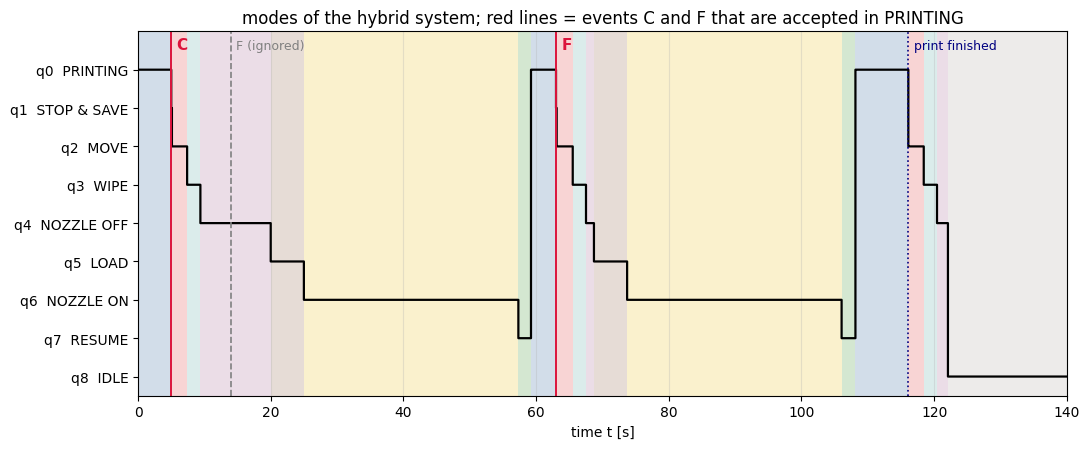

In [ ]:
COL = {'q0': '#4c78a8', 'q1': '#f58518', 'q2': '#e45756', 'q3': '#72b7b2', 'q4': '#b279a2',
       'q5': '#9d755d', 'q6': '#eeca3b', 'q7': '#54a24b', 'q8': '#bab0ac'}
idx = {q: i for i, q in enumerate(NAMES)}
segs, s0 = [], 0
for i in range(1, len(t) + 1):
    if i == len(t) or modes[i] != modes[s0]:
        segs.append((t[s0], t[i-1], modes[s0])); s0 = i

def shade(ax, alpha=0.25):
    for ta, tb, q in segs: ax.axvspan(ta, tb, color=COL[q], alpha=alpha, lw=0)

fig, ax = plt.subplots(figsize=(11, 4.6))
shade(ax)
ax.step(t, [idx[q] for q in modes], where='post', color='k', lw=1.6)
ax.set_yticks(range(9)); ax.set_yticklabels([f"{q}  {NAMES[q]}" for q in NAMES]); ax.set_ylim(8.5, -1.0)
for te, fr, to, ev in trans:
    if ev in ('C', 'F'):
        ax.axvline(te, color='crimson', lw=1.4); ax.text(te + 0.8, -0.55, ev, color='crimson', fontsize=11, weight='bold')
    elif 'ignored' in ev:
        ax.axvline(te, color='gray', lw=1.2, ls='--'); ax.text(te + 0.8, -0.55, ev.split()[0] + ' (ignored)', color='gray', fontsize=9)
    elif ev == 'print_finished':
        ax.axvline(te, color='navy', lw=1.2, ls=':'); ax.text(te + 0.8, -0.55, 'print finished', color='navy', fontsize=9)
ax.set_xlim(0, T_END); ax.set_xlabel('time t [s]'); ax.grid(alpha=0.3, axis='x')
ax.set_title('modes of the hybrid system; red lines = events C and F that are accepted in PRINTING')
plt.tight_layout(); plt.savefig('fig_q3_modes.png', dpi=200); plt.show()

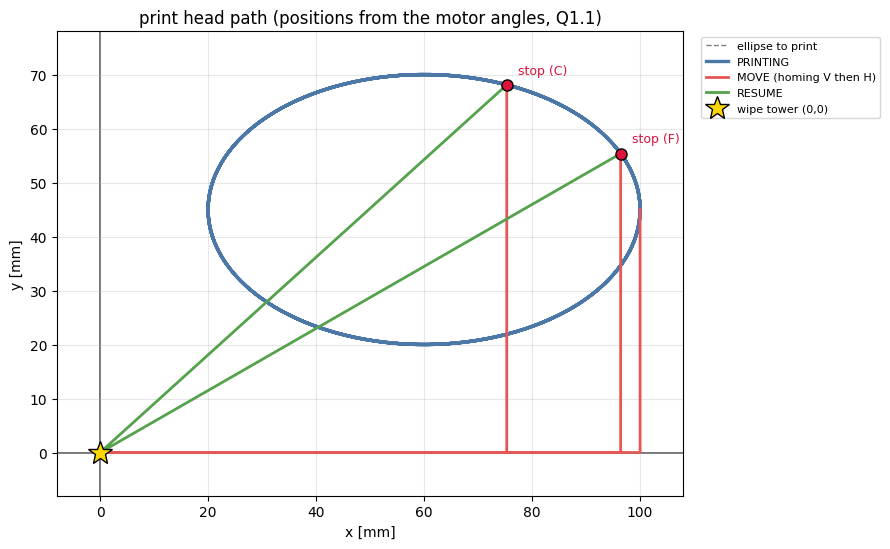

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
th = np.linspace(0, 2*np.pi, 400)
ax.plot((xc + A_el*np.cos(th))*1e3, (yc + B_el*np.sin(th))*1e3, color='gray', ls='--', lw=1, label='ellipse to print')
for q, lab in [('q0', 'PRINTING'), ('q2', 'MOVE (homing V then H)'), ('q7', 'RESUME')]:
    s = modes == q; xs, ys = np.where(s, xh, np.nan)*1e3, np.where(s, yh, np.nan)*1e3
    ax.plot(xs, ys, color=COL[q], lw=2.4 if q == 'q0' else 2.0, label=lab, zorder=3 if q != 'q0' else 2, ls='-')
for te, fr, to, ev in trans:
    if fr == 'q0' and to == 'q1':
        k = np.argmin(np.abs(t - te)); ax.plot(xh[k]*1e3, yh[k]*1e3, 'o', color='crimson', ms=8, mec='k', zorder=5)
        ax.annotate(f'stop ({ev})', (xh[k]*1e3, yh[k]*1e3), xytext=(8, 8), textcoords='offset points', fontsize=9, color='crimson')
ax.plot(0, 0, '*', color='gold', ms=18, mec='k', zorder=6, label='wipe tower (0,0)')
ax.axhline(0, color='0.35', lw=1.2, zorder=1); ax.axvline(0, color='0.35', lw=1.2, zorder=1)
ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.set_xlim(-8, 108); ax.set_ylim(-8, 78); ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=8)
ax.set_title('print head path (positions from the motor angles, Q1.1)')
plt.tight_layout(); plt.savefig('fig_q3_path.png', dpi=200); plt.show()

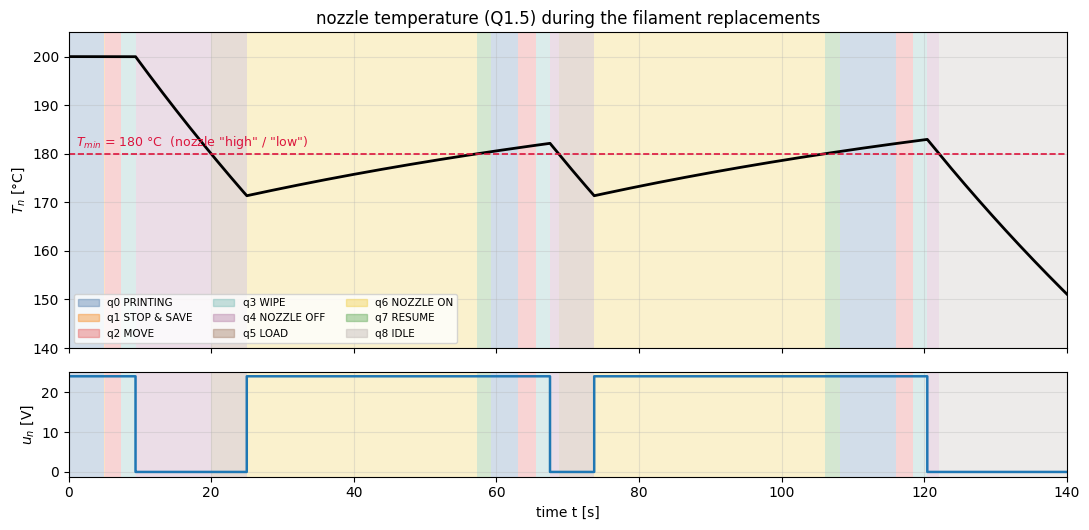

In [ ]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for a_ in (a1, a2): shade(a_)
a1.plot(t, X[:, 6], color='k', lw=2); a1.axhline(T_min, color='crimson', ls='--', lw=1.2)
a1.text(1, T_min + 1.5, '$T_{min}$ = 180 °C  (nozzle "high" / "low")', color='crimson', ha='left', fontsize=9)
a1.set_ylim(140, 205)
a1.set_ylabel('$T_n$ [°C]'); a1.grid(alpha=0.3); a1.set_title('nozzle temperature (Q1.5) during the filament replacements')
a2.plot(t, R['u'][:, 2], color='tab:blue', lw=1.8); a2.set_ylabel('$u_n$ [V]'); a2.set_xlabel('time t [s]'); a2.set_xlim(0, T_END); a2.grid(alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[q], alpha=0.4) for q in NAMES]
a1.legend(handles, [f'{q} {NAMES[q]}' for q in NAMES], ncol=3, fontsize=7.5, loc='lower left', bbox_to_anchor=(0.0, 0.0))
plt.tight_layout(); plt.savefig('fig_q3_nozzle.png', dpi=200); plt.show()

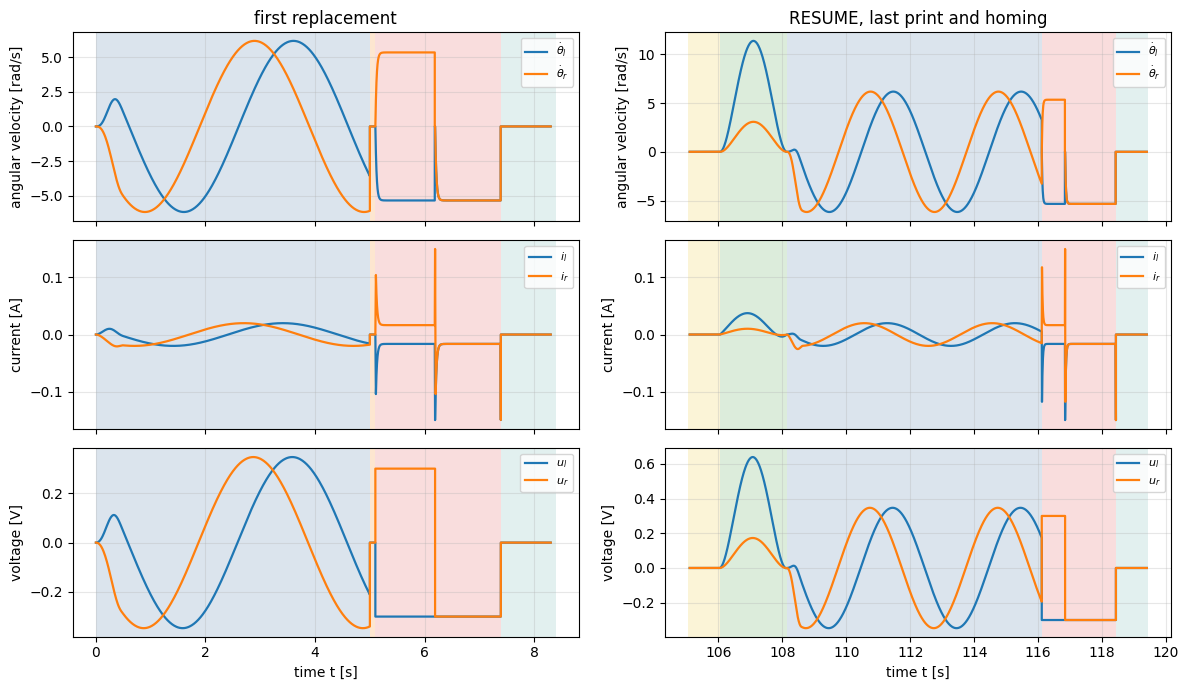

In [ ]:
t_q3_first = [tr[0] for tr in trans if tr[2] == 'q3'][0]
t_resume_last = [tr[0] for tr in trans if tr[1] == 'q6' and tr[2] == 'q7'][-1]
t_fin_end = [tr[0] for tr in trans if tr[1] == 'q2' and tr[2] == 'q3'][-1]
wins = [(0, t_q3_first + 1.0), (t_resume_last - 1.0, t_fin_end + 1.0)]
fig, axs = plt.subplots(3, 2, figsize=(12, 7), sharex='col')
for j, (wa, wb) in enumerate(wins):
    k = (t >= wa) & (t <= wb)
    for i, (cols, labs, yl) in enumerate([((2, 3), ('$\\dot\\theta_l$', '$\\dot\\theta_r$'), 'angular velocity [rad/s]'),
                                           ((4, 5), ('$i_l$', '$i_r$'), 'current [A]')]):
        for cidx, lb in zip(cols, labs): axs[i, j].plot(t[k], X[k, cidx], lw=1.6, label=lb)
        axs[i, j].set_ylabel(yl); axs[i, j].legend(loc='upper right', fontsize=8); axs[i, j].grid(alpha=0.3)
    axs[2, j].plot(t[k], R['u'][k, 0], lw=1.6, label='$u_l$'); axs[2, j].plot(t[k], R['u'][k, 1], lw=1.6, label='$u_r$')
    axs[2, j].set_ylabel('voltage [V]'); axs[2, j].set_xlabel('time t [s]'); axs[2, j].legend(loc='upper right', fontsize=8); axs[2, j].grid(alpha=0.3)
    for i in range(3):
        for ta, tb, q in segs:
            if tb >= wa and ta <= wb: axs[i, j].axvspan(max(ta, wa), min(tb, wb), color=COL[q], alpha=0.2, lw=0)
    axs[0, j].set_title(['first replacement', 'RESUME, last print and homing'][j])
plt.tight_layout(); plt.savefig('fig_q3_motors.png', dpi=200); plt.show()

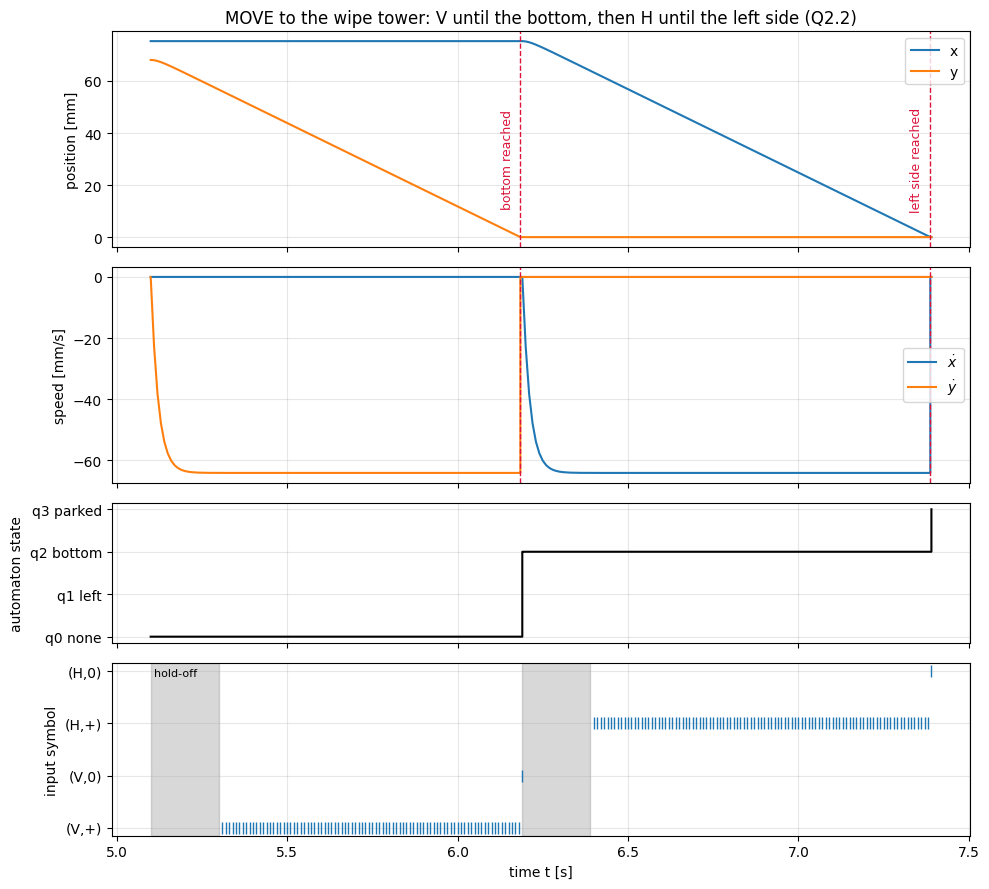

2

In [ ]:
mv = moves[0]; ta, tb = [tr[0] for tr in trans if tr[2] == 'q2'][0], [tr[0] for tr in trans if tr[1] == 'q2'][0]
k = (t >= ta) & (t <= tb) & (modes == 'q2')
fig, axs = plt.subplots(4, 1, figsize=(10, 9), sharex=True, gridspec_kw={'height_ratios': [2, 2, 1.3, 1.6]})
axs[0].plot(t[k], xh[k]*1e3, label='x'); axs[0].plot(t[k], yh[k]*1e3, label='y'); axs[0].set_ylabel('position [mm]'); axs[0].legend(loc='upper right')
vx = rm*(X[k, 2] + X[k, 3])*1e3; vy = rm*(X[k, 2] - X[k, 3])*1e3
axs[1].plot(t[k], vx, label='$\\dot x$'); axs[1].plot(t[k], vy, label='$\\dot y$'); axs[1].set_ylabel('speed [mm/s]'); axs[1].legend(loc='center right')
for te, what in mv['events']:
    for a_ in axs[:2]: a_.axvline(te, color='crimson', ls='--', lw=1)
    axs[0].text(te - 0.02, 30, what, color='crimson', fontsize=9, rotation=90, va='center', ha='right')
st = {'q0': 0, 'q1': 1, 'q2': 2, 'q3': 3}
axs[2].step(np.r_[t[k], tb], [st[d] for d in R['dfa'][k]] + [3], where='post', color='k'); axs[2].set_yticks(range(4))
axs[2].set_yticklabels(['q0 none', 'q1 left', 'q2 bottom', 'q3 parked']); axs[2].set_ylabel('automaton state')
sym_y = {'V+': 0, 'V0': 1, 'H+': 2, 'H0': 3}
sm = [(s[0], sym_y[s[1]]) for s in mv['samples']]
axs[3].plot([s[0] for s in sm], [s[1] for s in sm], '|', color='tab:blue', ms=9)
axs[3].set_yticks(range(4)); axs[3].set_yticklabels(['(V,+)', '(V,0)', '(H,+)', '(H,0)']); axs[3].set_ylabel('input symbol')
axs[3].axvspan(ta, ta + t_hold, color='gray', alpha=0.3); axs[3].text(ta + 0.01, 2.9, 'hold-off', fontsize=8)
t_sw = [s[0] for s in mv['samples'] if s[3] == 'q2' and s[2] == 'q0'][0]
axs[3].axvspan(t_sw, t_sw + t_hold, color='gray', alpha=0.3)
axs[3].set_xlabel('time t [s]')
for a_ in axs: a_.grid(alpha=0.3)
axs[0].set_title('MOVE to the wipe tower: V until the bottom, then H until the left side (Q2.2)')
plt.tight_layout(); plt.savefig('fig_q3_homing.png', dpi=200); plt.show()

i

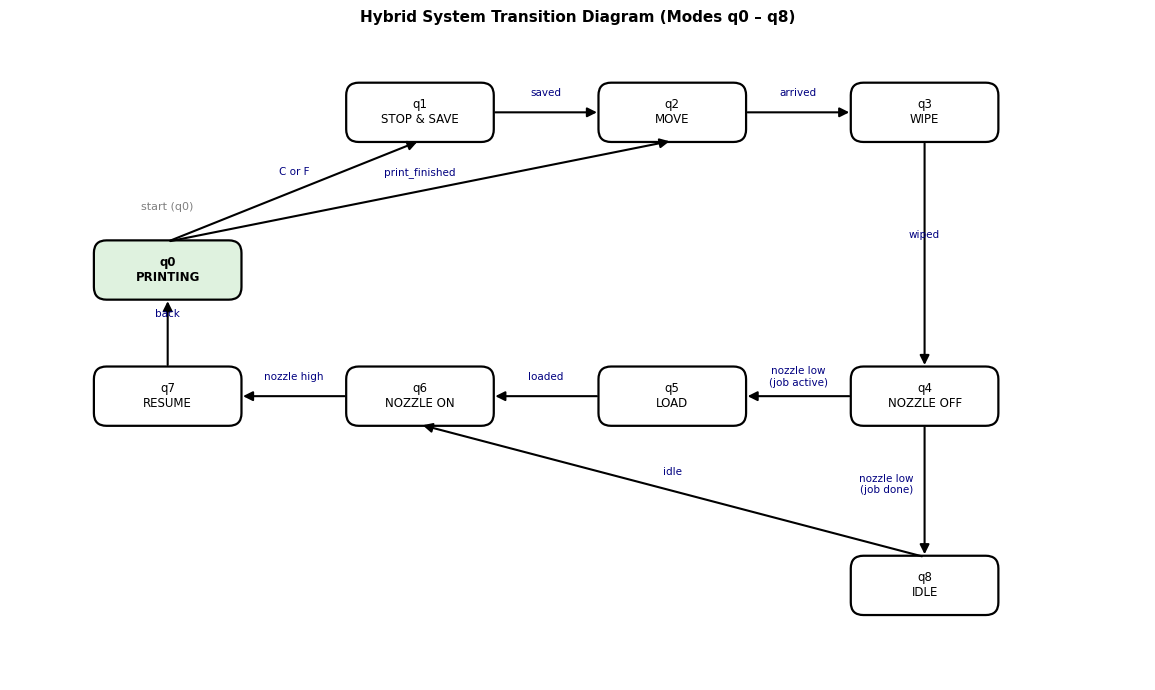

In [ ]:
# Layout coordinates for the 9 hybrid modes (q0 to q8)
pos = {
    'q0': (0, 0),
    'q1': (4, 2.5),
    'q2': (8, 2.5),
    'q3': (12, 2.5),
    'q4': (12, -2),
    'q5': (8, -2),
    'q6': (4, -2),
    'q7': (0, -2),
    'q8': (12, -5.0)
}
w, h = 2.3, 0.9

fig, ax = plt.subplots(figsize=(13, 7))

# Draw mode boxes
for name, (x, y) in pos.items():
    label_text = f"{name}\n{NAMES.get(name, '')}"
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.2",
                                fc="#dff2df" if name == 'q0' else "white", ec="k", lw=1.6))
    ax.text(x, y, label_text, ha="center", va="center", fontsize=8.5, weight="bold" if name == 'q0' else "normal")

# Arrow drawing helper function
def draw_transition(src, dst, label, label_off=(0, 0.3)):
    (x1, y1), (x2, y2) = pos[src], pos[dst]
    if y1 == y2:
        s = 1 if x2 > x1 else -1
        q1, p2 = (x1 + s*w/2, y1), (x2 - s*w/2, y2)
    else:
        s = 1 if y2 > y1 else -1
        q1, p2 = (x1, y1 + s*h/2), (x2, y2 - s*h/2)
    ax.add_patch(FancyArrowPatch(q1, p2, arrowstyle="-|>", mutation_scale=14, lw=1.5, color="k"))
    ax.text((q1[0] + p2[0])/2 + label_off[0], (q1[1] + p2[1])/2 + label_off[1],
            label, ha="center", va="center", fontsize=7.5, color="navy")

# Define hybrid system transitions (Source, Destination, Guard/Event)
hybrid_transitions = [
    ('q0', 'q1', 'C or F'),
    ('q0', 'q2', 'print_finished'),
    ('q1', 'q2', 'saved'),
    ('q2', 'q3', 'arrived'),
    ('q3', 'q4', 'wiped'),
    ('q4', 'q5', 'nozzle low\n(job active)'),
    ('q4', 'q8', 'nozzle low\n(job done)'),
    ('q5', 'q6', 'loaded'),
    ('q6', 'q7', 'nozzle high'),
    ('q7', 'q0', 'back'),
    ('q8', 'q6', 'idle'),
]

for src, dst, label in hybrid_transitions:
    # Adjust offsets for vertical vs horizontal links to prevent label overlap
    off = (-0.6, 0.1) if src == 'q4' and dst == 'q8' else (0, 0.3)
    draw_transition(src, dst, label, label_off=off)

ax.text(0, 0.95, "start (q0)", ha="center", fontsize=8, color="gray")
ax.set_xlim(-2.5, 15.5)
ax.set_ylim(-6.5, 3.8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Hybrid System Transition Diagram (Modes q0 – q8)", fontsize=11, weight="bold")
plt.tight_layout()
plt.savefig("fig_q3_system_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

### Q3.2

In [ ]:
# Printing square
x_start, y_start = 0.05, 0.05
side_len = 0.05
s_speed = 0.05
t_side = side_len / s_speed

ext_q3 = [(5.0, 'C'), (14.0, 'F'), (63.0, 'F')]
T_END = 100.0

# References for each side
S  = lambda u: 10*u**3 - 15*u**4 + 6*u**5
S1 = lambda u: 30*u**2 - 60*u**3 + 30*u**4
S2 = lambda u: 60*u - 180*u**2 + 120*u**3
S3 = lambda u: 60 - 360*u + 360*u**2


class SquarePrintRef:

    def __init__(self, t0):
        self.t0 = t0
        self.x0, self.y0 = x_start, y_start
        self.L = side_len
        self.s = s_speed
        self.T_side = self.L / self.s

    def get_submode(self, t):
        tau = t - self.t0
        if tau < self.T_side:
            return 'q0.1', tau, 0.0, self.s
        elif tau < 2 * self.T_side:
            return 'q0.2', tau - self.T_side, self.s, 0.0
        elif tau < 3 * self.T_side:
            return 'q0.3', tau - 2 * self.T_side, 0.0, -self.s
        elif tau <= 4 * self.T_side:
            return 'q0.4', tau - 3 * self.T_side, -self.s, 0.0
        else:
            return 'finished', self.T_side, 0.0, 0.0

    def d(self, t):
        mode, tau, xd_val, yd_val = self.get_submode(t)
        if mode == 'q0.1':
            xv, yv = self.x0, self.y0 + yd_val * tau
        elif mode == 'q0.2':
            xv, yv = self.x0 + xd_val * tau, self.y0 + self.L
        elif mode == 'q0.3':
            xv, yv = self.x0 + self.L, self.y0 + self.L + yd_val * tau
        elif mode == 'q0.4':
            xv, yv = self.x0 + self.L + xd_val * tau, self.y0
        else:
            xv, yv = self.x0, self.y0

        xd = [xv, xd_val, 0.0, 0.0]
        yd = [yv, yd_val, 0.0, 0.0]
        return xd, yd

pos = lambda x: (rm*(x[0] + x[1]), rm*(x[0] - x[1]))
stop = lambda x: np.r_[x[:2], np.zeros(4), x[6:]]

NAMES = {
    'q0.1': 'PRINT V UP', 'q0.2': 'PRINT H RIGHT', 'q0.3': 'PRINT V DOWN', 'q0.4': 'PRINT H LEFT',
    'q1': 'STOP & SAVE', 'q2': 'MOVE', 'q3': 'WIPE', 'q4': 'NOZZLE OFF',
    'q5': 'LOAD', 'q6': 'NOZZLE ON', 'q7': 'RESUME', 'q8': 'IDLE'
}

def inputs(mode, cx, t, x):
    if mode in ('q0.1', 'q0.2', 'q0.3', 'q0.4', 'q7'):
        ul, ur = volts(cx['ref'], t); return ul, ur, U_ON, False
    if mode == 'q2':
        ux, uy = (-u_home, 0.) if cx['cmd'] == 'H' else (0., -u_home)
        return (ux + uy)/2, (ux - uy)/2, U_ON, False
    if mode in ('q1', 'q3', 'q6'): return 0., 0., U_ON, True
    return 0., 0., 0., True

def guards(mode, cx):
    if mode in ('q0.1', 'q0.2', 'q0.3'):
        # Transition to next side sub-mode based on time elapsed on current side
        g = lambda t, x: (t - cx['t0']) - t_side; g.direction = 1; return [(f'{mode}_done', g)]
    if mode == 'q0.4':
        g = lambda t, x: (t - cx['t0']) - t_side; g.direction = 1; return [('print_finished', g)]
    if mode == 'q1': g = lambda t, x: t - (cx['t0'] + t_save); g.direction = 1; return [('saved', g)]
    if mode == 'q3': g = lambda t, x: t - (cx['t0'] + t_wipe); g.direction = 1; return [('wiped', g)]
    if mode == 'q4': g = lambda t, x: x[6] - T_min;            g.direction = -1; return [('nozzle low', g)]
    if mode == 'q5': g = lambda t, x: t - (cx['t0'] + t_load); g.direction = 1; return [('loaded', g)]
    if mode == 'q6': g = lambda t, x: x[6] - T_min;            g.direction = 1; return [('nozzle high', g)]
    if mode == 'q7': g = lambda t, x: t - (cx['t0'] + cx['ref'].T); g.direction = 1; return [('back', g)]
    return []

DT_FAST, DT_SLOW = 0.01, 0.1
def sample_grid(t_a, t_b, dt):
    k0 = int(np.floor(t_a/dt)) + 1
    g = np.arange(k0, int(np.floor(t_b/dt)) + 1)*dt
    return np.r_[t_a, g[(g > t_a) & (g < t_b)], t_b]

def log_seg(L, mode, cx, sol, t_a, t_b, dt):
    tg = sample_grid(t_a, t_b, dt)
    for tt, yy in zip(tg, sol.sol(tg).T):
        ul, ur, un, _ = inputs(mode, cx, tt, yy)
        L['t'].append(tt); L['x'].append(yy); L['mode'].append(mode)
        L['u'].append((ul, ur, un)); L['dfa'].append(cx.get('dfa', '-'))

def advance_generic(mode, cx, t, x, t_stop, L):
    gs = guards(mode, cx)
    def rhs(tt, xx):
        ul, ur, un, fr = inputs(mode, cx, tt, xx); return f_plant(xx, ul, ur, un, fr)
    evs = []
    for _, g in gs: g.terminal = True; evs.append(g)
    sol = solve_ivp(rhs, (t, t_stop), x, method='Radau', rtol=1e-8, atol=1e-10, events=evs or None, dense_output=True)
    t_end = sol.t[-1]
    is_print_mode = mode in ('q0.1', 'q0.2', 'q0.3', 'q0.4', 'q7')
    log_seg(L, mode, cx, sol, t, t_end, DT_FAST if is_print_mode else DT_SLOW)
    fired = None
    for (name, _), te in zip(gs, sol.t_events or []):
        if len(te): fired = name
    return t_end, sol.y[:, -1].copy(), fired

def advance_move(cx, t, x, t_stop, L):
    while t < t_stop - 1e-12:
        t_next = min(cx['t_next_sample'], t_stop)
        def rhs(tt, xx):
            ul, ur, un, fr = inputs('q2', cx, tt, xx); return f_plant(xx, ul, ur, un, fr, cx['bX'], cx['bY'])
        gy = lambda tt, xx: pos(xx)[1]; gy.terminal = True; gy.direction = -1
        gx = lambda tt, xx: pos(xx)[0]; gx.terminal = True; gx.direction = -1
        sol = solve_ivp(rhs, (t, t_next), x, method='Radau', rtol=1e-8, atol=1e-10, events=[gy, gx], dense_output=True)
        te = sol.t[-1]; log_seg(L, 'q2', cx, sol, t, te, DT_FAST)
        x = sol.y[:, -1].copy(); t = te
        if len(sol.t_events[0]):
            cx['bY'] = True; w = 0.5*(x[2] + x[3]); x[2] = x[3] = w; cx['events'].append((t, 'bottom reached'))
        if len(sol.t_events[1]):
            cx['bX'] = True; w = 0.5*(x[2] - x[3]); x[2], x[3] = w, -w; cx['events'].append((t, 'left side reached'))
        if t >= cx['t_next_sample'] - 1e-12:
            cx['t_next_sample'] += Ts
            if t - cx['t_cmd'] >= t_hold:
                wV, wH = abs(x[2] - x[3]), abs(x[2] + x[3])
                sym = cx['cmd'] + ('+' if (wV if cx['cmd'] == 'V' else wH) > eps_w else '0')
                nxt = DELTA.get((cx['dfa'], sym))
                cx['samples'].append((t, sym, cx['dfa'], nxt))
                if nxt is None: raise RuntimeError(f"automaton rejected {sym} in {cx['dfa']}")
                cx['dfa'] = nxt
                if nxt == 'q2' and cx['cmd'] == 'V': cx['cmd'], cx['t_cmd'] = 'H', t
                if nxt == 'q3': return t, x, 'arrived'
    return t, x, None

def new_move_ctx(t):
    return dict(t0=t, dfa='q0', cmd='V', t_cmd=t, t_next_sample=t + Ts, bX=False, bY=False, events=[], samples=[])

def transition(mode, new, ev, t, x, cx, mem):
    if mode in ('q0.1', 'q0.2', 'q0.3', 'q0.4'):
        if ev in ('C', 'F'):
            mem['xp'], mem['yp'] = pos(x)
        else:
            mem['job_done'] = True
    if mode in ('q0.1', 'q0.2', 'q0.3', 'q0.4', 'q2', 'q7'): x = stop(x)

    if   new == 'q2': cx = new_move_ctx(t)
    elif new == 'q7': cx = dict(ref=P2P(t, pos(x), (mem['xp'], mem['yp'])), t0=t)
    elif new in ('q0.1', 'q0.2', 'q0.3', 'q0.4'): cx = dict(ref=mem['square_ref'], t0=t)
    else:             cx = dict(t0=t)
    return x, cx

def run_hybrid(ext_events=ext_q3, t_end=T_END):
    x = np.zeros(9)
    X0, Y0 = x_start, y_start
    x[0], x[1] = (X0 + Y0)/(2*rm), (X0 - Y0)/(2*rm); x[6:] = [200.0, U_ON, U_ON/Rn]

    sq_ref = SquarePrintRef(0.0)
    t, mode, cx = 0.0, 'q0.1', dict(ref=sq_ref, t0=0.0)
    mem = dict(job_done=False, xp=None, yp=None, square_ref=sq_ref)
    L = dict(t=[], x=[], mode=[], u=[], dfa=[]); trans, moves = [], []
    ext = sorted(ext_events)

    while t < t_end - 1e-9:
        t_stop = min(t_end, ext[0][0]) if ext else t_end
        t, x, fired = advance_move(cx, t, x, t_stop, L) if mode == 'q2' else advance_generic(mode, cx, t, x, t_stop, L)
        new = ev = None

        if fired:
            ev = fired
            if mode == 'q0.1': new = 'q0.2'
            elif mode == 'q0.2': new = 'q0.3'
            elif mode == 'q0.3': new = 'q0.4'
            elif mode == 'q0.4': new = 'q2' # finished square sides -> go home/wipe
            else:
                new = {'q1': 'q2', 'q2': 'q3', 'q3': 'q4', 'q5': 'q6', 'q6': 'q7', 'q7': 'q0.1',
                       'q4': 'q8' if mem['job_done'] else 'q5'}[mode]
            if mode == 'q2': moves.append(cx)
        elif ext and abs(t - ext[0][0]) < 1e-9:
            _, name = ext.pop(0)
            if mode in ('q0.1', 'q0.2', 'q0.3', 'q0.4'):
                ev, new = name, 'q1' # C or F triggers filament replacement during printing
            else:
                trans.append((t, mode, mode, f'{name} ignored'))

        if new:
            x, cx = transition(mode, new, ev, t, x, cx, mem)
            trans.append((t, mode, new, ev)); mode = new

    R = {k: np.array(v) for k, v in L.items()}; R['mem'] = mem
    return R, trans, moves

# Run the simulation
R, trans, moves = run_hybrid()
t, X, modes = R['t'], R['x'], R['mode']
xh, yh = rm*(X[:, 0] + X[:, 1]), rm*(X[:, 0] - X[:, 1])

print("Simulation finished successfully with square sub-modes!")

Simulation finished successfully with square sub-modes!


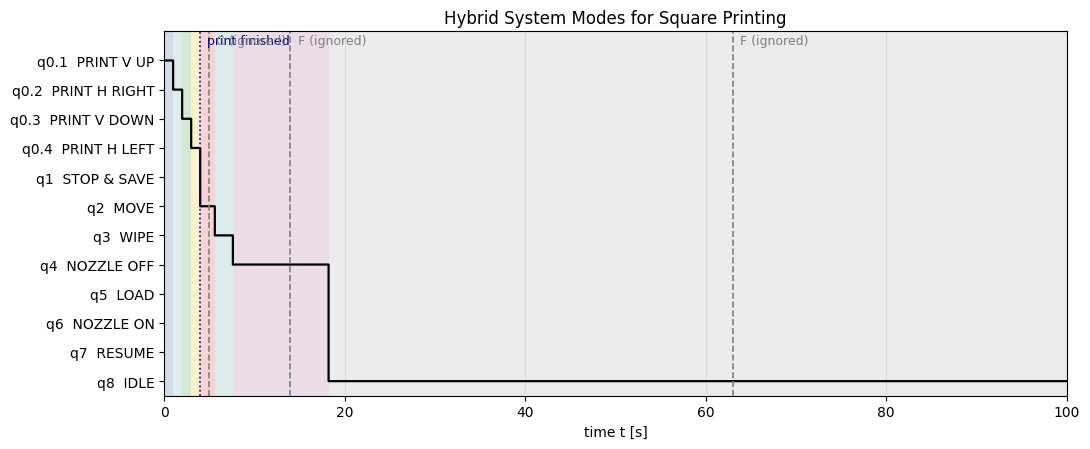

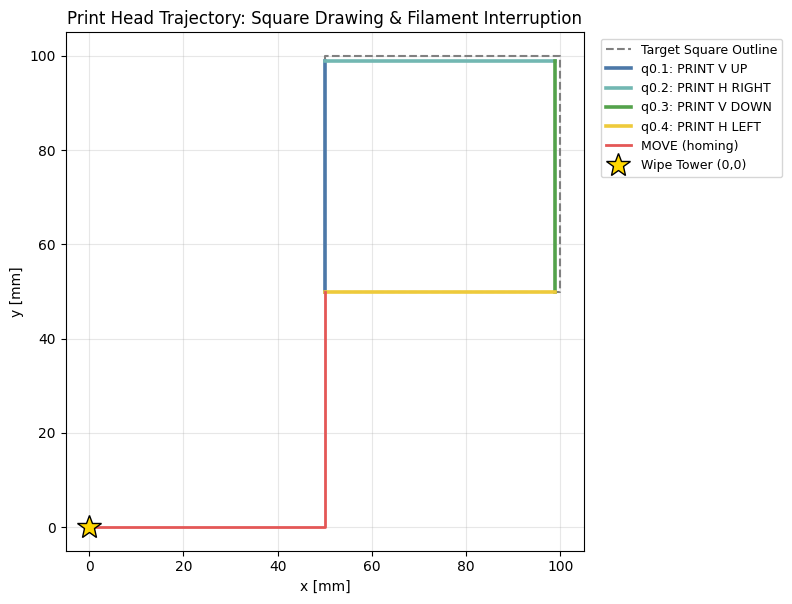

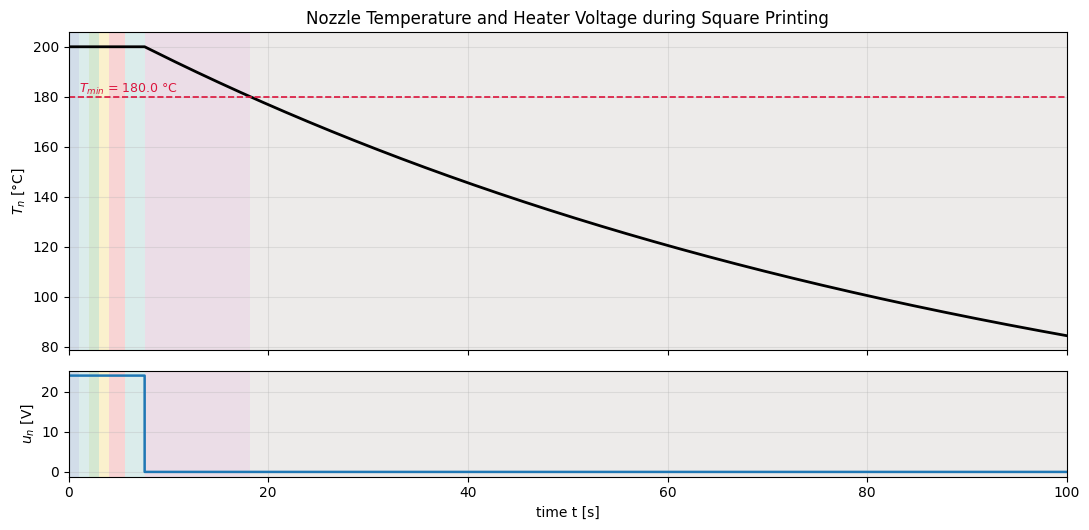

In [ ]:
# Extended color map including the 4 square sub-modes
COL = {
    'q0.1': '#4c78a8', 'q0.2': '#72b7b2', 'q0.3': '#54a24b', 'q0.4': '#eeca3b',
    'q1': '#f58518',   'q2': '#e45756',   'q3': '#72b7b2',   'q4': '#b279a2',
    'q5': '#9d755d',   'q6': '#eeca3b',   'q7': '#54a24b',   'q8': '#bab0ac'
}

idx = {q: i for i, q in enumerate(NAMES)}
segs, s0 = [], 0
for i in range(1, len(t) + 1):
    if i == len(t) or modes[i] != modes[s0]:
        segs.append((t[s0], t[i-1], modes[s0])); s0 = i

def shade(ax, alpha=0.25):
    for ta, tb, q in segs:
        if q in COL:
            ax.axvspan(ta, tb, color=COL[q], alpha=alpha, lw=0)

# Modes and Events over Time
fig, ax = plt.subplots(figsize=(11, 4.6))
shade(ax)
ax.step(t, [idx[q] for q in modes], where='post', color='k', lw=1.6)
ax.set_yticks(range(len(NAMES)))
ax.set_yticklabels([f"{q}  {NAMES[q]}" for q in NAMES])
ax.set_ylim(len(NAMES) - 0.5, -1.0)

for te, fr, to, ev in trans:
    if ev in ('C', 'F'):
        ax.axvline(te, color='crimson', lw=1.4)
        ax.text(te + 0.8, -0.55, ev, color='crimson', fontsize=11, weight='bold')
    elif 'ignored' in ev:
        ax.axvline(te, color='gray', lw=1.2, ls='--')
        ax.text(te + 0.8, -0.55, ev.split()[0] + ' (ignored)', color='gray', fontsize=9)
    elif ev == 'print_finished':
        ax.axvline(te, color='navy', lw=1.2, ls=':')
        ax.text(te + 0.8, -0.55, 'print finished', color='navy', fontsize=9)

ax.set_xlim(0, T_END)
ax.set_xlabel('time t [s]')
ax.grid(alpha=0.3, axis='x')
ax.set_title('Hybrid System Modes for Square Printing')
plt.tight_layout()
plt.savefig('fig_square_modes.png', dpi=200)
plt.show()


# Print Head Path (Square Trajectory)
fig, ax = plt.subplots(figsize=(8, 8))
sq_x_outline = np.array([x_start, x_start, x_start + side_len, x_start + side_len, x_start]) * 1e3
sq_y_outline = np.array([y_start, y_start + side_len, y_start + side_len, y_start, y_start]) * 1e3
ax.plot(sq_x_outline, sq_y_outline, color='gray', ls='--', lw=1.5, label='Target Square Outline')

for q_sub, lab in [('q0.1', 'PRINT V UP'), ('q0.2', 'PRINT H RIGHT'),
                   ('q0.3', 'PRINT V DOWN'), ('q0.4', 'PRINT H LEFT')]:
    sel = (modes == q_sub)
    if np.any(sel):
        ax.plot(xh[sel]*1e3, yh[sel]*1e3, color=COL[q_sub], lw=2.6, label=f'{q_sub}: {lab}')

for q_mov, lab in [('q2', 'MOVE (homing)'), ('q7', 'RESUME')]:
    sel = (modes == q_mov)
    if np.any(sel):
        ax.plot(xh[sel]*1e3, yh[sel]*1e3, color=COL[q_mov], lw=2.0, ls='-', label=lab)

for te, fr, to, ev in trans:
    if 'q0' in fr and to == 'q1':
        k = np.argmin(np.abs(t - te))
        ax.plot(xh[k]*1e3, yh[k]*1e3, 'o', color='crimson', ms=8, mec='k', zorder=5)
        ax.annotate(f'stop ({ev})', (xh[k]*1e3, yh[k]*1e3), xytext=(8, 8), textcoords='offset points', fontsize=9, color='crimson')

ax.plot(0, 0, '*', color='gold', ms=18, mec='k', zorder=6, label='Wipe Tower (0,0)')
ax.set_xlabel('x [mm]')
ax.set_ylabel('y [mm]')
ax.set_aspect('equal')
ax.grid(alpha=0.3)
ax.set_title('Print Head Trajectory: Square Drawing & Filament Interruption')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=9)
plt.tight_layout()
plt.savefig('fig_square_path.png', dpi=200)
plt.show()


# Nozzle Temperature and Heater Voltage
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for a_ in (a1, a2): shade(a_)

a1.plot(t, X[:, 6], color='k', lw=2)
a1.axhline(T_min, color='crimson', ls='--', lw=1.2)
a1.text(1, T_min + 1.5, f'$T_{{min}}$ = {T_min} °C', color='crimson', ha='left', fontsize=9)
a1.set_ylabel('$T_n$ [°C]')
a1.grid(alpha=0.3)
a1.set_title('Nozzle Temperature and Heater Voltage during Square Printing')

a2.plot(t, R['u'][:, 2], color='tab:blue', lw=1.8)
a2.set_ylabel('$u_n$ [V]')
a2.set_xlabel('time t [s]')
a2.set_xlim(0, T_END)
a2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_square_nozzle.png', dpi=200)
plt.show()